**Libraries used in the EDA**

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
import folium
from folium.plugins import HeatMap
from scipy.stats import chi2_contingency



In [2]:
from google.colab import drive
drive.mount('/content/drive')

# Please update these paths with the correct locations of your CSV files in Google Drive
# Example: crash = pd.read_csv('/content/drive/MyDrive/my_folder/cleaned_crash_data.csv')
crash = pd.read_csv('/content/drive/MyDrive/cleaned_crash_data.csv')
traffic = pd.read_csv('/content/drive/MyDrive/cleaned_traffic_data.csv')

print("Crash data loaded:", crash.shape)
print("Traffic data loaded:", traffic.shape)

Mounted at /content/drive
Crash data loaded: (92082, 50)
Traffic data loaded: (170747, 10)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
print("\n--- CRASH DATA INFO ---")
print(crash.info())

print("\n--- TRAFFIC DATA INFO ---")
print(traffic.info())

print("\n--- CRASH FIRST 5 ROWS ---")
display(crash.head())

print("\n--- TRAFFIC FIRST 5 ROWS ---")
display(traffic.head())

**Crash severity distribution**

degree_of_crash
injury                    61187
non-casualty (towaway)    29507
fatal                      1388
Name: count, dtype: int64


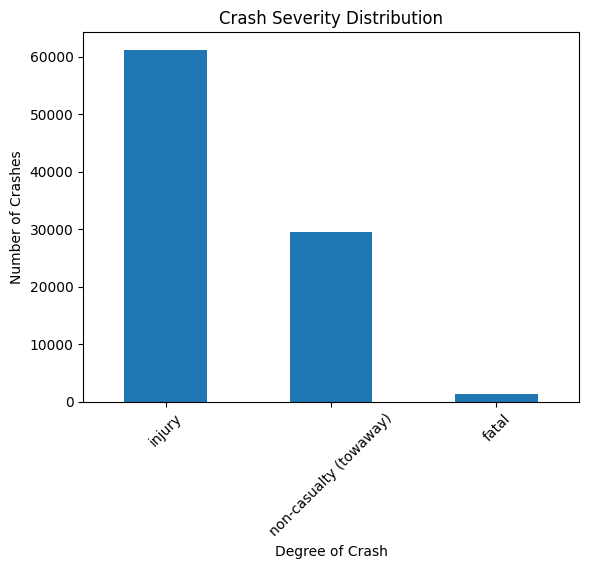

In [3]:
severity_count = crash['degree_of_crash'].value_counts()

print(severity_count)

severity_count.plot(kind='bar')
plt.title('Crash Severity Distribution')
plt.xlabel('Degree of Crash')
plt.ylabel('Number of Crashes')
plt.xticks(rotation=45)
plt.show()

**Crashes by year**

year_of_crash
2020    18764
2021    17413
2022    18255
2023    18711
2024    18939
Name: count, dtype: int64


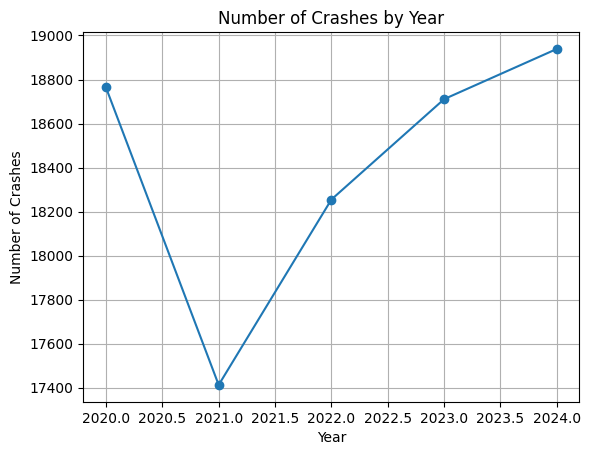

In [4]:
crashes_by_year = crash['year_of_crash'].value_counts().sort_index()

print(crashes_by_year)

crashes_by_year.plot(kind='line', marker='o')
plt.title('Number of Crashes by Year')
plt.xlabel('Year')
plt.ylabel('Number of Crashes')
plt.grid(True)
plt.show()

**By Month**

month_of_crash
january      6949
february     7514
march        8148
april        7206
may          8381
june         7952
july         7552
august       7459
september    7297
october      7705
november     7983
december     7936
Name: count, dtype: int64


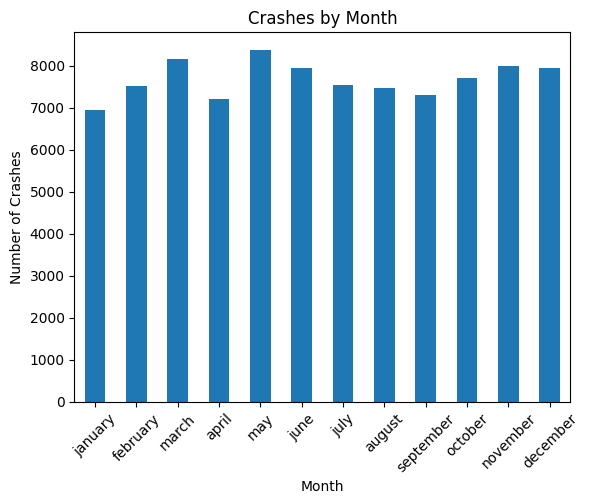

In [5]:
month_order = [
    'january', 'february', 'march', 'april', 'may', 'june',
    'july', 'august', 'september', 'october', 'november', 'december'
]

crashes_by_month = crash['month_of_crash'].value_counts().reindex(month_order)

print(crashes_by_month)

crashes_by_month.plot(kind='bar')
plt.title('Crashes by Month')
plt.xlabel('Month')
plt.ylabel('Number of Crashes')
plt.xticks(rotation=45)
plt.show()

**by day of week**

day_of_week_of_crash
monday       12180
tuesday      12741
wednesday    13557
thursday     13793
friday       14658
saturday     13556
sunday       11597
Name: count, dtype: int64


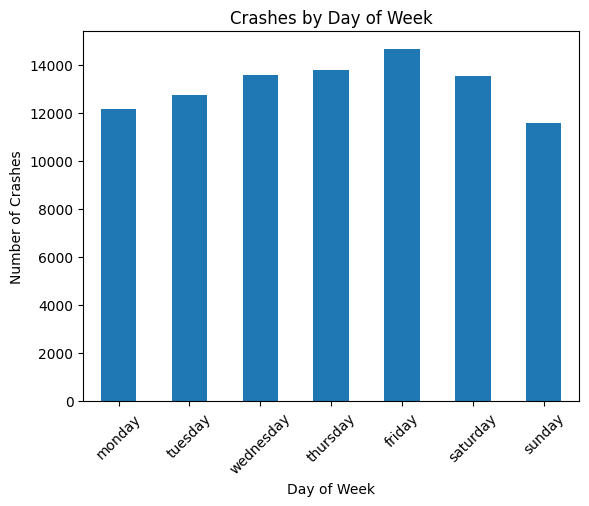

In [6]:
day_order = [
    'monday', 'tuesday', 'wednesday', 'thursday',
    'friday', 'saturday', 'sunday'
]

crashes_by_day = crash['day_of_week_of_crash'].value_counts().reindex(day_order)

print(crashes_by_day)

crashes_by_day.plot(kind='bar')
plt.title('Crashes by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Number of Crashes')
plt.xticks(rotation=45)
plt.show()

**by Time interval**

two-hour_intervals
16:00 - 17:59       13457
14:00 - 15:59       12837
12:00 - 13:59       10658
10:00 - 11:59        9791
08:00 - 09:59        9405
18:00 - 19:59        9108
06:00 - 07:59        7172
20:00 - 21:59        6315
22:00 - midnight     4957
00:01 - 01:59        3073
04:00 - 05:59        3072
02:00 - 03:59        2232
unknown                 5
Name: count, dtype: int64


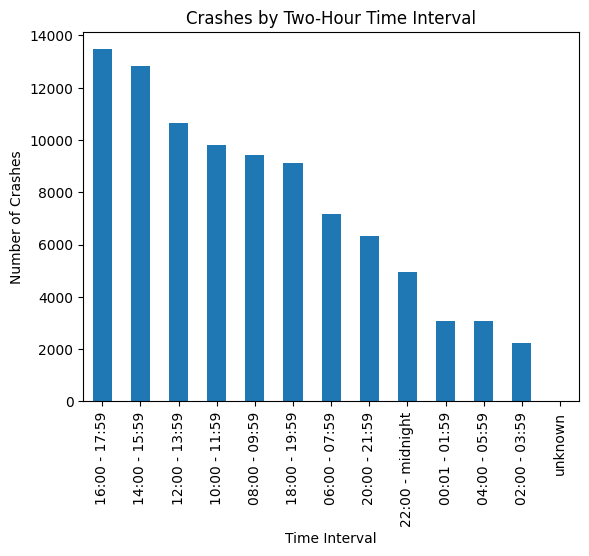

In [7]:
crashes_by_time = crash['two-hour_intervals'].value_counts()

print(crashes_by_time)

crashes_by_time.plot(kind='bar')
plt.title('Crashes by Two-Hour Time Interval')
plt.xlabel('Time Interval')
plt.ylabel('Number of Crashes')
plt.xticks(rotation=90)
plt.show()

**Top 10 LGAs with most crashes**

lga
canterbury-bankstown    4573
central coast           4369
blacktown               4295
sydney                  2932
parramatta              2874
cumberland              2837
liverpool               2812
fairfield               2481
wollongong              2271
newcastle               2254
Name: count, dtype: int64


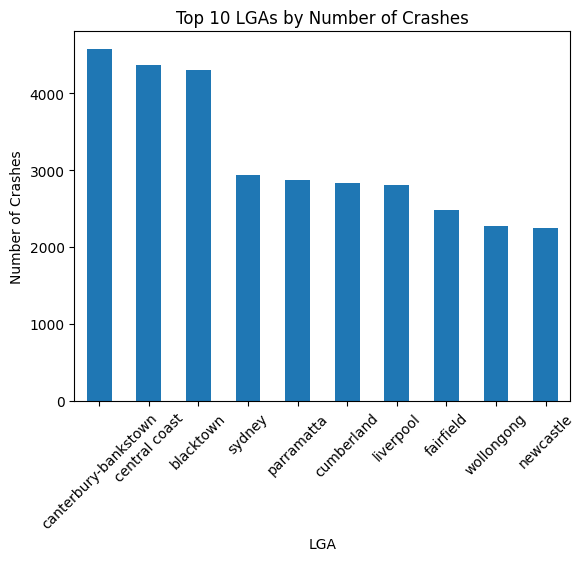

In [8]:
top_lga = crash['lga'].value_counts().head(10)

print(top_lga)

top_lga.plot(kind='bar')
plt.title('Top 10 LGAs by Number of Crashes')
plt.xlabel('LGA')
plt.ylabel('Number of Crashes')
plt.xticks(rotation=45)
plt.show()

**Fatality rate per LGA**

=== Top 10 LGAs by Fatality Rate (min 100 crashes) ===
degree_of_crash  total  fatal  fatality_rate_%
lga                                           
federation         147     15            10.20
narromine          101      8             7.92
warrumbungle       197     13             6.60
forbes             141      9             6.38
greater hume       245     15             6.12
tenterfield        165     10             6.06
narrabri           188     11             5.85
inverell           261     15             5.75
bland              111      6             5.41
cowra              186     10             5.38


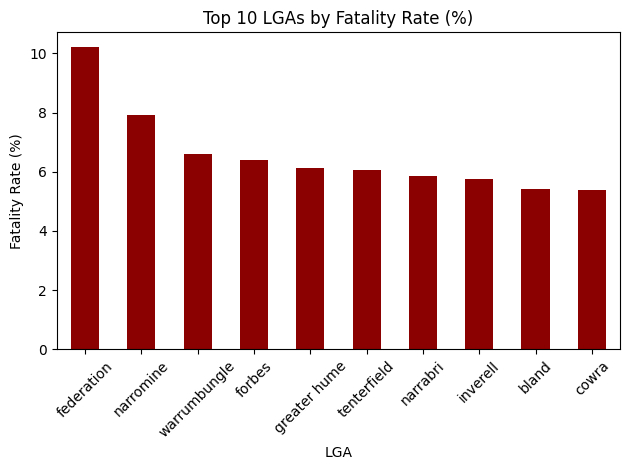

In [9]:
# Fatality Rate by LGA
lga_severity = crash.groupby('lga')['degree_of_crash'].value_counts().unstack(fill_value=0)
lga_severity['total'] = lga_severity.sum(axis=1)
lga_severity['fatality_rate_%'] = (lga_severity.get('fatal', 0) / lga_severity['total'] * 100).round(2)

# To only show LGAs with at least 100 crashes to avoid any statistical noise
high_volume = lga_severity[lga_severity['total'] >= 100]
top_fatal_rate = high_volume.nlargest(10, 'fatality_rate_%')[['total', 'fatal', 'fatality_rate_%']]

print("=== Top 10 LGAs by Fatality Rate (min 100 crashes) ===")
print(top_fatal_rate)

top_fatal_rate['fatality_rate_%'].plot(kind='bar', color='darkred')
plt.title('Top 10 LGAs by Fatality Rate (%)')
plt.xlabel('LGA')
plt.ylabel('Fatality Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Top 10 towns with most crashes**

town
bankstown        645
blacktown        609
dubbo            562
sydney           531
liverpool        522
coffs harbour    462
merrylands       459
lidcombe         445
greenacre        442
auburn           438
Name: count, dtype: int64


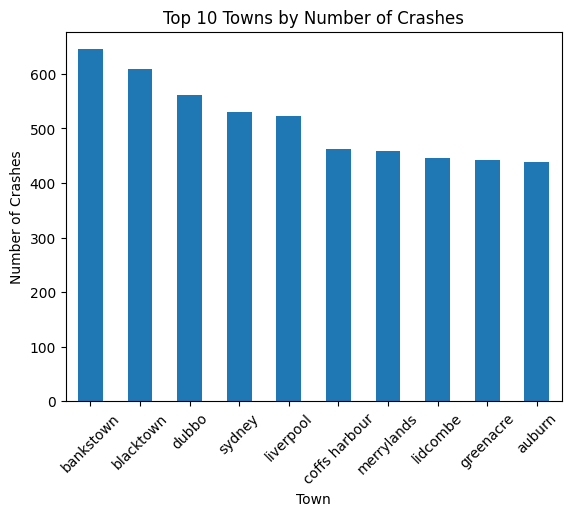

In [10]:
top_town = crash['town'].value_counts().head(10)

print(top_town)

top_town.plot(kind='bar')
plt.title('Top 10 Towns by Number of Crashes')
plt.xlabel('Town')
plt.ylabel('Number of Crashes')
plt.xticks(rotation=45)
plt.show()

**Weather condition analysis**

weather
fine           72502
raining        11386
overcast        6141
unknown         1143
fog or mist      641
other            179
snowing           90
Name: count, dtype: int64


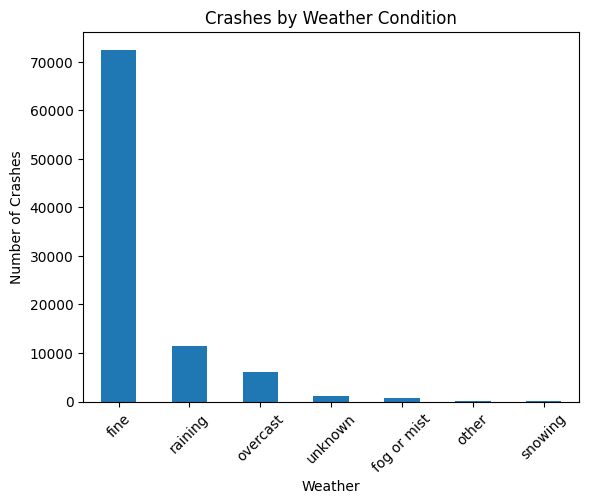

In [11]:
weather_count = crash['weather'].value_counts()

print(weather_count)

weather_count.plot(kind='bar')
plt.title('Crashes by Weather Condition')
plt.xlabel('Weather')
plt.ylabel('Number of Crashes')
plt.xticks(rotation=45)
plt.show()

**Weather vs crash severity**

degree_of_crash  fatal  injury  non-casualty (towaway)
weather                                               
fine              1077   49186                   22239
fog or mist         15     375                     251
other                5     103                      71
overcast           129    3752                    2260
raining            145    6928                    4313
snowing              2      51                      37
unknown             15     792                     336


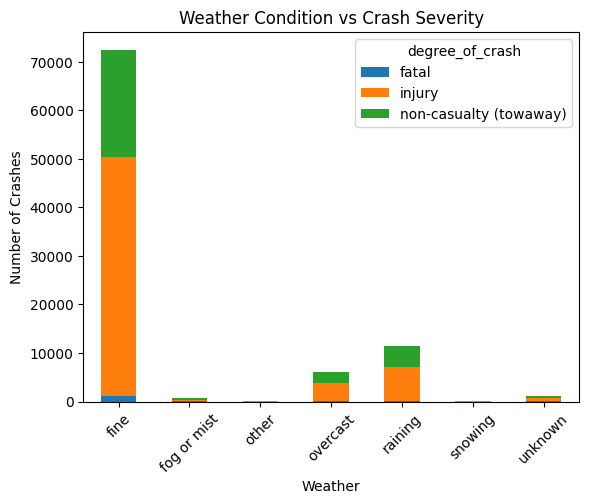

In [12]:
weather_severity = pd.crosstab(
    crash['weather'],
    crash['degree_of_crash']
)

print(weather_severity)

weather_severity.plot(kind='bar', stacked=True)
plt.title('Weather Condition vs Crash Severity')
plt.xlabel('Weather')
plt.ylabel('Number of Crashes')
plt.xticks(rotation=45)
plt.show()

**Road surface condition analysis**

surface_condition
dry            74671
wet            16650
unknown          615
snow or ice      146
Name: count, dtype: int64


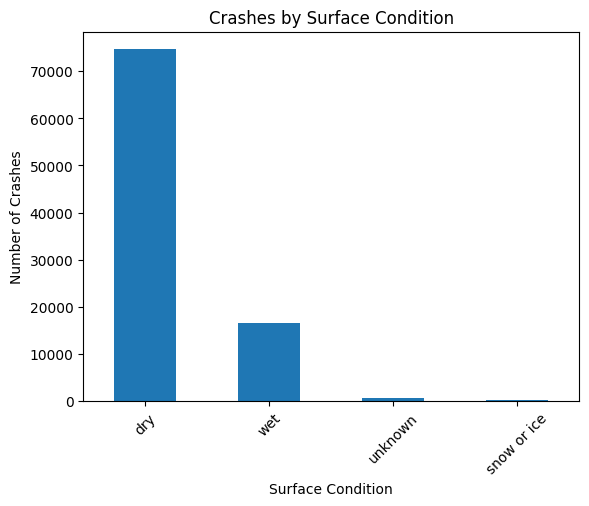

In [13]:
surface_condition_count = crash['surface_condition'].value_counts()

print(surface_condition_count)

surface_condition_count.plot(kind='bar')
plt.title('Crashes by Surface Condition')
plt.xlabel('Surface Condition')
plt.ylabel('Number of Crashes')
plt.xticks(rotation=45)
plt.show()

**Natural lighting analysis**

natural_lighting
daylight    59413
darkness    23606
dusk         5527
dawn         3103
unknown       433
Name: count, dtype: int64


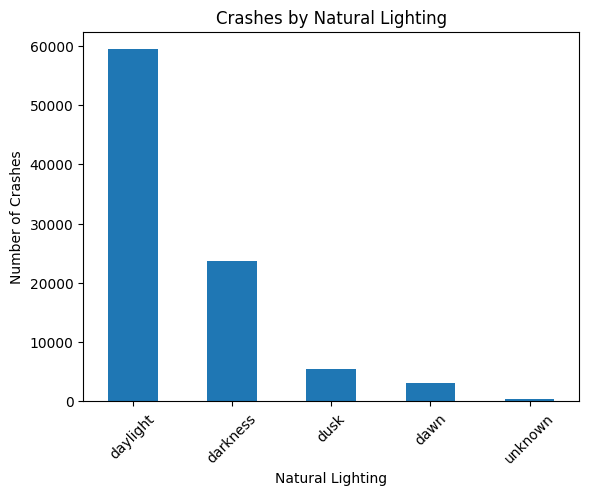

In [14]:
lighting_count = crash['natural_lighting'].value_counts()

print(lighting_count)

lighting_count.plot(kind='bar')
plt.title('Crashes by Natural Lighting')
plt.xlabel('Natural Lighting')
plt.ylabel('Number of Crashes')
plt.xticks(rotation=45)
plt.show()

**Speed limit analysis**

speed_limit
50 km/h     30656
60 km/h     25194
100 km/h    10296
80 km/h      8897
70 km/h      7709
110 km/h     3868
40 km/h      3848
90 km/h      1289
30 km/h       193
10 km/h        66
20 km/h        40
unknown        26
Name: count, dtype: int64


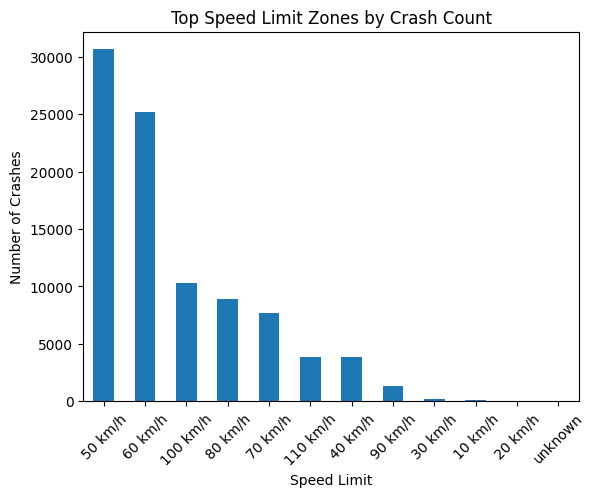

In [15]:
speed_count = crash['speed_limit'].value_counts().head(15)

print(speed_count)

speed_count.plot(kind='bar')
plt.title('Top Speed Limit Zones by Crash Count')
plt.xlabel('Speed Limit')
plt.ylabel('Number of Crashes')
plt.xticks(rotation=45)
plt.show()

**Crash severity by speed Limit**

=== Crash Severity by Speed Limit ===
degree_of_crash  fatal  injury  non-casualty (towaway)  total  fatal_rate_%
speed_limit                                                                
100 km/h           451    6773                    3072  10296          4.38
110 km/h           114    2219                    1535   3868          2.95
20 km/h              1      32                       7     40          2.50
80 km/h            211    6358                    2328   8897          2.37
10 km/h              1      53                      12     66          1.52
90 km/h             19     867                     403   1289          1.47
70 km/h             97    5318                    2294   7709          1.26
60 km/h            219   17224                    7751  25194          0.87
50 km/h            254   19346                   11056  30656          0.83
40 km/h             21    2814                    1013   3848          0.55
30 km/h              0     166                    

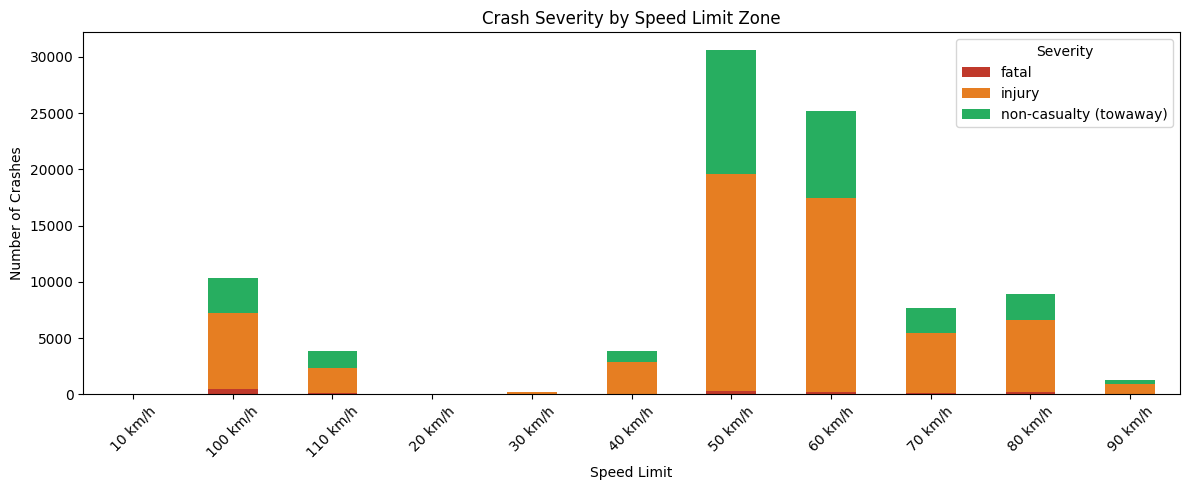

In [16]:
# Crash Severity by Speed Limit
speed_sev = crash[crash['speed_limit'] != 'unknown'].copy()
speed_sev_table = pd.crosstab(speed_sev['speed_limit'], speed_sev['degree_of_crash'])

# Calculating fatality rate per speed zone
speed_sev_table['total'] = speed_sev_table.sum(axis=1)
speed_sev_table['fatal_rate_%'] = (speed_sev_table.get('fatal', 0) / speed_sev_table['total'] * 100).round(2)

print("=== Crash Severity by Speed Limit ===")
print(speed_sev_table.sort_values('fatal_rate_%', ascending=False))

speed_sev_table[['fatal', 'injury', 'non-casualty (towaway)']].plot(
    kind='bar', stacked=True, figsize=(12, 5),
    color=['#C0392B', '#E67E22', '#27AE60']
)
plt.title('Crash Severity by Speed Limit Zone')
plt.xlabel('Speed Limit')
plt.ylabel('Number of Crashes')
plt.xticks(rotation=45)
plt.legend(title='Severity')
plt.tight_layout()
plt.show()

**Vehicle type analysis using traffic data**

tu_type_group
car/car derivative       114333
light truck               25312
motorcycle                11002
pedestrian                 5167
pedal cycle                3840
heavy rigid truck          3502
other motor vehicle        2924
articulated truck          2882
bus                         997
non-motorised vehicle       412
other or unknown            376
Name: count, dtype: int64


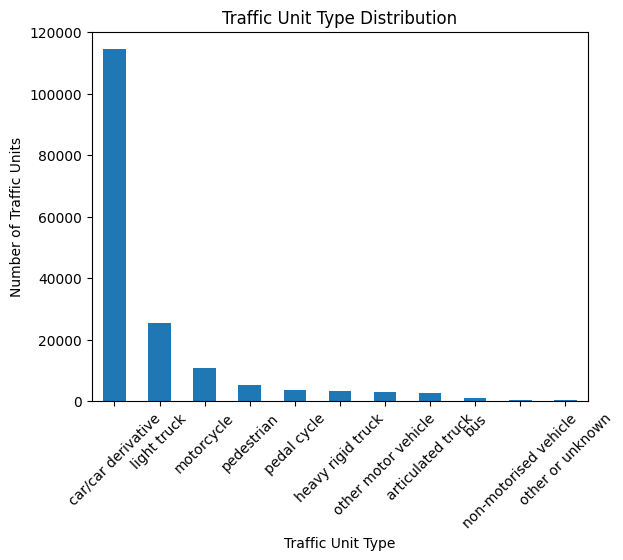

In [17]:
vehicle_count = traffic['tu_type_group'].value_counts()

print(vehicle_count)

vehicle_count.plot(kind='bar')
plt.title('Traffic Unit Type Distribution')
plt.xlabel('Traffic Unit Type')
plt.ylabel('Number of Traffic Units')
plt.xticks(rotation=45)
plt.show()

**Traffic unit role in first impact**

tu_role_in_first_impact
key traffic unit                  92082
other traffic unit                64070
traffic unit not in 1st impact    14595
Name: count, dtype: int64


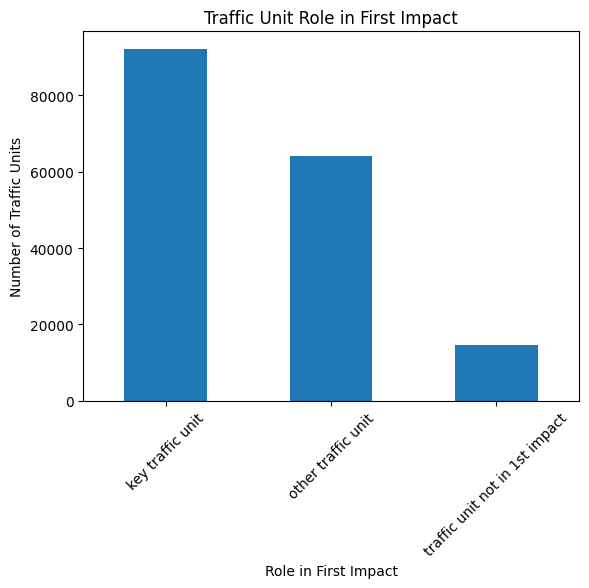

In [18]:
impact_role_count = traffic['tu_role_in_first_impact'].value_counts()

print(impact_role_count)

impact_role_count.plot(kind='bar')
plt.title('Traffic Unit Role in First Impact')
plt.xlabel('Role in First Impact')
plt.ylabel('Number of Traffic Units')
plt.xticks(rotation=45)
plt.show()

**Manoeuvre analysis**

manoeuvre
proceeding in lane         100117
turning right               13747
stationary                  12968
parked                      12249
other forward                4380
incorrect side               4022
turning left                 3751
walk across carriageway      2603
forward from drive           2096
veering left                 1597
veering right                1582
perform u-turn               1566
wait turn right              1371
pulling out                  1263
along footpath               1006
Name: count, dtype: int64


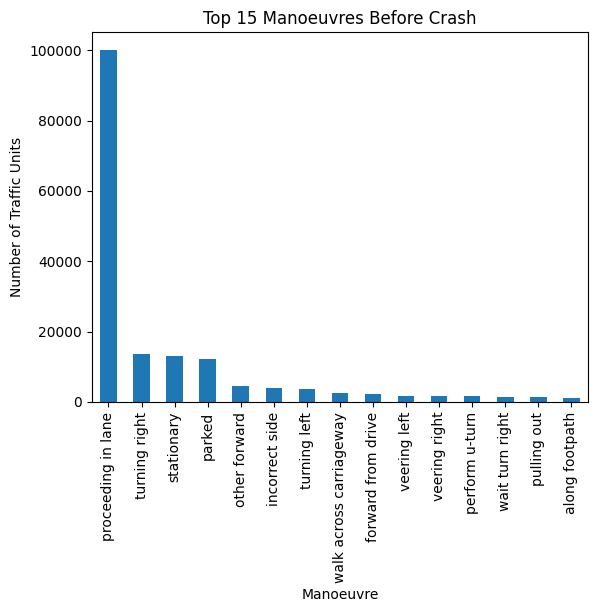

In [19]:
manoeuvre_count = traffic['manoeuvre'].value_counts().head(15)

print(manoeuvre_count)

manoeuvre_count.plot(kind='bar')
plt.title('Top 15 Manoeuvres Before Crash')
plt.xlabel('Manoeuvre')
plt.ylabel('Number of Traffic Units')
plt.xticks(rotation=90)
plt.show()

**Vehicle type vs crash severity**

degree_of_crash        fatal  injury  non-casualty (towaway)
tu_type_group                                               
articulated truck        139    1617                    1126
bus                       30     668                     299
car/car derivative      1060   72707                   40566
heavy rigid truck        112    2150                    1240
light truck              432   16230                    8650
motorcycle               293   10184                     525
non-motorised vehicle      9     195                     208
other motor vehicle       25    1727                    1172
other or unknown           4      92                     280
pedal cycle               51    3762                      27
pedestrian               261    4892                      14


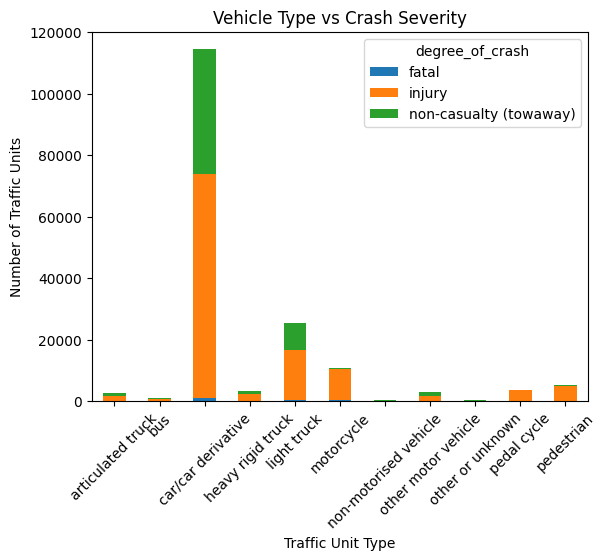

In [20]:
vehicle_severity = traffic.merge(
    crash[['crash_id', 'degree_of_crash']],
    on='crash_id',
    how='left'
)

vehicle_severity_table = pd.crosstab(
    vehicle_severity['tu_type_group'],
    vehicle_severity['degree_of_crash']
)

print(vehicle_severity_table)

vehicle_severity_table.plot(kind='bar', stacked=True)
plt.title('Vehicle Type vs Crash Severity')
plt.xlabel('Traffic Unit Type')
plt.ylabel('Number of Traffic Units')
plt.xticks(rotation=45)
plt.show()

**Object hit analysis**


=== Most Common Objects Hit in Crashes ===
object_hit_1
tree/bush                   150894
fence                         3477
utility pole                  2846
s/barrier - guardrail         2151
embankment                    1667
signpost                      1263
traffic island etc            1151
drain/culvert                  937
s/barrier - concr/jersey       804
building                       684
Name: count, dtype: int64


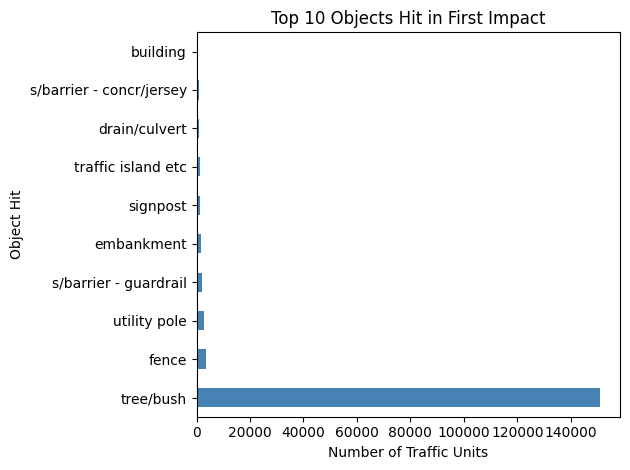

In [21]:
# Object Hit Analysis
print("\n=== Most Common Objects Hit in Crashes ===")
obj1 = traffic['object_hit_1'].value_counts().head(10)
print(obj1)

obj1.plot(kind='barh', color='steelblue')
plt.title('Top 10 Objects Hit in First Impact')
plt.xlabel('Number of Traffic Units')
plt.ylabel('Object Hit')
plt.tight_layout()
plt.show()

**School Zone**


=== Crashes in School Zones ===
Total crashes in school zones: 4889
Fatal in school zones: 36


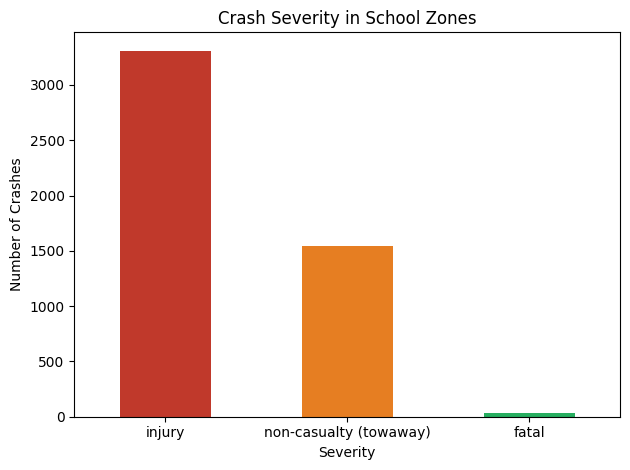

In [22]:
# School Zone Analysis
print("\n=== Crashes in School Zones ===")
school_crashes = crash[crash['school_zone_location'] == 'yes']
print(f"Total crashes in school zones: {len(school_crashes)}")
print(f"Fatal in school zones: {(school_crashes['degree_of_crash'] == 'fatal').sum()}")

school_sev = school_crashes['degree_of_crash'].value_counts()
school_sev.plot(kind='bar', color=['#C0392B', '#E67E22', '#27AE60'])
plt.title('Crash Severity in School Zones')
plt.xlabel('Severity')
plt.ylabel('Number of Crashes')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Chi-Square Test of Independence (Weather vs Crash Severity)**

In [23]:
# Create contingency table
contingency_table = pd.crosstab(crash['weather'], crash['degree_of_crash'])

print("=== Chi-Square Test: Weather vs Crash Severity ===\n")
print("Contingency Table:")
print(contingency_table)
print("\n" + "-"*50)

# Perform chi-square test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

# Print the results
print(f"\nChi-Square Statistic: {chi2:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"Degrees of Freedom: {dof}")

# and its Interpretation
alpha = 0.05
if p_value < alpha:
    print(f"\n✓ Result: Reject null hypothesis (p < {alpha})")
    print("  → There IS a significant association between weather and crash severity")
else:
    print(f"\n✗ Result: Fail to reject null hypothesis (p >= {alpha})")
    print("  → No significant association found")

=== Chi-Square Test: Weather vs Crash Severity ===

Contingency Table:
degree_of_crash  fatal  injury  non-casualty (towaway)
weather                                               
fine              1077   49186                   22239
fog or mist         15     375                     251
other                5     103                      71
overcast           129    3752                    2260
raining            145    6928                    4313
snowing              2      51                      37
unknown             15     792                     336

--------------------------------------------------

Chi-Square Statistic: 361.5664
P-value: 0.000000
Degrees of Freedom: 12

✓ Result: Reject null hypothesis (p < 0.05)
  → There IS a significant association between weather and crash severity


**For limit vs severity**

In [24]:
# Chi-Square Tests — speed vs Severity ──────
from scipy.stats import chi2_contingency

test_features = ['speed_limit', 'natural_lighting', 'surface_condition',
                 'day_of_week_of_crash', 'urbanisation']

print("\n=== Chi-Square Tests: Multiple Features vs Crash Severity ===\n")
for feat in test_features:
    ct = pd.crosstab(crash[feat], crash['degree_of_crash'])
    chi2, p, dof, _ = chi2_contingency(ct)
    result = "SIGNIFICANT ✓" if p < 0.05 else "not significant ✗"
    print(f"{feat:<35} chi2={chi2:.2f}  p={p:.4f}  → {result}")


=== Chi-Square Tests: Multiple Features vs Crash Severity ===

speed_limit                         chi2=1476.50  p=0.0000  → SIGNIFICANT ✓
natural_lighting                    chi2=1261.14  p=0.0000  → SIGNIFICANT ✓
surface_condition                   chi2=323.03  p=0.0000  → SIGNIFICANT ✓
day_of_week_of_crash                chi2=73.36  p=0.0000  → SIGNIFICANT ✓
urbanisation                        chi2=905.03  p=0.0000  → SIGNIFICANT ✓


**Correlation Matrix with Heatmap**

=== Correlation Matrix ===
                               no._killed  no._seriously_injured  \
no._killed                          1.000                  0.047   
no._seriously_injured               0.047                  1.000   
no._moderately_injured              0.037                 -0.122   
no._minor-other_injured            -0.014                 -0.128   
speed_limit                         0.085                  0.062   
no._of_traffic_units_involved      -0.016                 -0.025   

                               no._moderately_injured  \
no._killed                                      0.037   
no._seriously_injured                          -0.122   
no._moderately_injured                          1.000   
no._minor-other_injured                        -0.124   
speed_limit                                     0.027   
no._of_traffic_units_involved                   0.080   

                               no._minor-other_injured  speed_limit  \
no._killed               

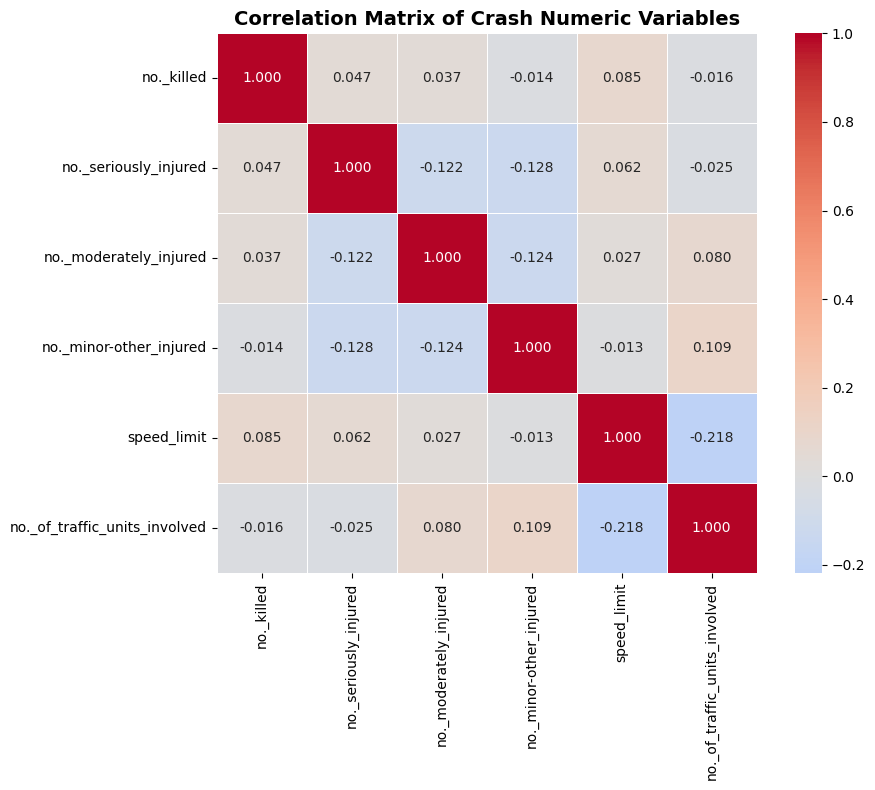

In [25]:

# Selecting numeric columns for correlation analysis
numeric_cols = ['no._killed', 'no._seriously_injured', 'no._moderately_injured', 'no._minor-other_injured', 'speed_limit',
                'no._of_traffic_units_involved']

# Make a copy to avoid modifying the original DataFrame in place if not intended
crash_processed = crash.copy()

# speed_limit column to numeric
# Removing ' km/h' and handle 'unknown'
crash_processed['speed_limit'] = crash_processed['speed_limit'].astype(str).str.replace(' km/h', '', regex=False)
crash_processed['speed_limit'] = crash_processed['speed_limit'].replace('unknown', np.nan)
crash_processed['speed_limit'] = pd.to_numeric(crash_processed['speed_limit'])

# any remaining NaN values in speed_limit are filled with its median!
crash_processed['speed_limit'] = crash_processed['speed_limit'].fillna(crash_processed['speed_limit'].median())

# Create correlation matrix using the processed DataFrame
correlation_matrix = crash_processed[numeric_cols].corr()

print("=== Correlation Matrix ===")
print(correlation_matrix.round(3))

# heatmap visualization
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix,
            annot=True,           # Show correlation values
            cmap='coolwarm',      # Red-blue color scheme
            center=0,             # Center colormap at 0
            fmt='.3f',            # 3 decimal places
            square=True,          # Square cells
            linewidths=0.5)       # Cell borders

plt.title('Correlation Matrix of Crash Numeric Variables', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


**Logistic Regression to Identify Key Risk Factors**

In [26]:
print("=== Logistic Regression: Predicting Crash Severity ===\n")

# a copy of the crash DataFrame for processing to avoid modifying the original
crash_model_df = crash.copy()

# two-hour_intervals to a numeric 'hour' feature
# Extract start hour (e.g., '16' from '16:00 - 17:59')
crash_model_df['hour'] = crash_model_df['two-hour_intervals'].astype(str).str.split(':').str[0]
crash_model_df['hour'] = crash_model_df['hour'].replace('unknown', np.nan)
crash_model_df['hour'] = pd.to_numeric(crash_model_df['hour'])
# fill with its median
crash_model_df['hour'] = crash_model_df['hour'].fillna(crash_model_df['hour'].median())

# Creating binary severity target (0 = non-fatal, 1 = fatal)
crash_model_df['severity_binary'] = (crash_model_df['degree_of_crash'] == 'fatal').astype(int)

# feature selection (predictors)
# Corrected column names
feature_cols = ['speed_limit', 'weather', 'natural_lighting', 'surface_condition', 'hour']

# Preparing features
X = crash_model_df[feature_cols].copy()

# Encoding categorical variables
label_encoders = {}
categorical_features = ['weather', 'natural_lighting', 'surface_condition'] # Corrected names

for col in categorical_features:
    le = LabelEncoder()
    # Handle missing values by treating 'Unknown' as a category
    X[col] = X[col].fillna('unknown') # Ensure  that the 'unknown' is a string for LabelEncoder
    X[col] = le.fit_transform(X[col])
    label_encoders[col] = le

# Target variable
y = crash_model_df['severity_binary']

# Handle the missing values in numeric columns
# 'speed_limit' was cleaned in a previous cell, but re-clean just in case for this model!
crash_model_df['speed_limit'] = crash_model_df['speed_limit'].astype(str).str.replace(' km/h', '', regex=False)
crash_model_df['speed_limit'] = crash_model_df['speed_limit'].replace('unknown', np.nan)
crash_model_df['speed_limit'] = pd.to_numeric(crash_model_df['speed_limit'])
X['speed_limit'] = crash_model_df['speed_limit'].fillna(crash_model_df['speed_limit'].median())
X['hour'] = crash_model_df['hour'].fillna(crash_model_df['hour'].median()) # Already handled above, but good practice

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train the model
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

# Make predictions
y_pred = model.predict(X_test_scaled)

# Evaluate it
print("Model Performance:\n")
# Adjust target_names to match the binary classification
print(classification_report(y_test, y_pred, target_names=['Non-Fatal', 'Fatal']))

# Feature importance (Odds Ratios)
print("\n=== Feature Importance (Odds Ratios) ===\n")
coefficients = model.coef_[0]
odds_ratios = np.exp(coefficients)

feature_importance = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': coefficients,
    'Odds_Ratio': odds_ratios
})
feature_importance = feature_importance.sort_values('Odds_Ratio', ascending=False)

print(feature_importance.to_string(index=False))
print("\nInterpretation: Odds Ratio > 1 increases crash severity risk")
print("              Odds Ratio < 1 decreases crash severity risk")

=== Logistic Regression: Predicting Crash Severity ===

Model Performance:

              precision    recall  f1-score   support

   Non-Fatal       0.99      1.00      0.99     18151
       Fatal       0.00      0.00      0.00       266

    accuracy                           0.99     18417
   macro avg       0.49      0.50      0.50     18417
weighted avg       0.97      0.99      0.98     18417


=== Feature Importance (Odds Ratios) ===

          Feature  Coefficient  Odds_Ratio
      speed_limit     0.599628    1.821442
          weather     0.030512    1.030982
             hour    -0.006993    0.993031
surface_condition    -0.126406    0.881257
 natural_lighting    -0.165246    0.847685

Interpretation: Odds Ratio > 1 increases crash severity risk
              Odds Ratio < 1 decreases crash severity risk


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


**Merge Crash Data with Traffic Data**

In [27]:
# merging
print("Crash Data Columns:", crash.columns.tolist())
print("\nTraffic Data Columns:", traffic.columns.tolist())

# Finding common identifier
if 'crash_id' in crash.columns and 'crash_id' in traffic.columns:
    # Direct merge on crash_id
    merged_df = pd.merge(crash, traffic, on='crash_id', how='left')
    print(f"\n✓ Merged on 'crash_id'")

elif 'lga' in crash.columns and 'lga' in traffic.columns:
    # Merge on LGA (Local Government Area) for aggregate analysis
    # 'lga' is in lower case in codes
    merged_df = pd.merge(crash, traffic, on='lga', how='left')
    print(f"\n✓ Merged on 'lga'")

else:
    print("\nCould not find common key for merging. Please check column names or define a custom merge key.")
    merged_df = pd.DataFrame() # an empty DataFrame to avoid errors later

print(f"\nMerged DataFrame shape: {merged_df.shape}")
print(f"Columns after merge: {merged_df.columns.tolist()}")

Crash Data Columns: ['crash_id', 'degree_of_crash', 'degree_of_crash_-_detailed', 'reporting_year', 'year_of_crash', 'month_of_crash', 'day_of_week_of_crash', 'two-hour_intervals', 'street_of_crash', 'street_type', 'distance', 'direction', 'identifying_feature', 'identifying_feature_type', 'town', 'route_no.', 'school_zone_location', 'school_zone_active', 'type_of_location', 'latitude', 'longitude', 'lga', 'urbanisation', 'conurbation_1', 'alignment', 'primary_permanent_feature', 'primary_temporary_feature', 'primary_hazardous_feature', 'street_lighting', 'road_surface', 'surface_condition', 'weather', 'natural_lighting', 'signals_operation', 'other_traffic_control', 'speed_limit', 'road_classification_(admin)', 'rum_-_code', 'rum_-_description', 'dca_-_code', 'dca_-_description', 'dca_supplement', 'first_impact_type', 'key_tu_type', 'other_tu_type', 'no._of_traffic_units_involved', 'no._killed', 'no._seriously_injured', 'no._moderately_injured', 'no._minor-other_injured']

Traffic Dat

**Time Series Decomposition (Monthly Crash Trends)**

=== Time Series Decomposition: Monthly Crash Trends ===



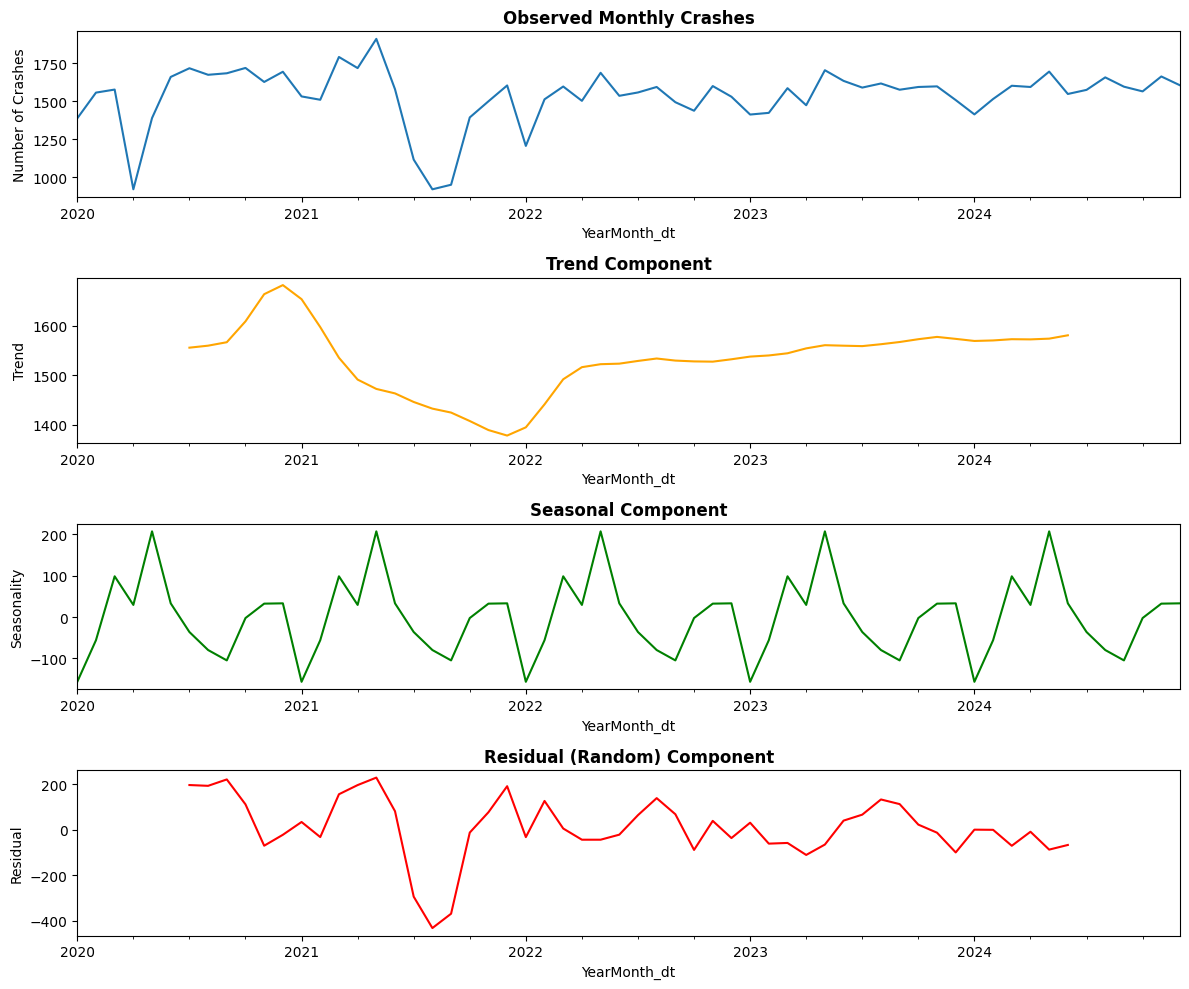


Interpretation:
- Trend shows long-term direction (increasing/decreasing crashes)
- Seasonal shows repeating patterns (e.g., more crashes in certain months)
- Residual is random variation not explained by trend/seasonality


In [28]:
# Aggregate crashes by month
# First, create a 'Crash_Date' from 'reporting_year' and 'month_of_crash'
# Map month names to numbers
month_mapping = {
    'january': 1, 'february': 2, 'march': 3, 'april': 4, 'may': 5, 'june': 6,
    'july': 7, 'august': 8, 'september': 9, 'october': 10, 'november': 11, 'december': 12
}
crash['month_num'] = crash['month_of_crash'].map(month_mapping)
crash['Crash_Date'] = pd.to_datetime(crash['reporting_year'].astype(str) + '-' + crash['month_num'].astype(str) + '-01', errors='coerce')

crash_cleaned = crash.dropna(subset=['Crash_Date'])

# Now aggregation
crash_cleaned['YearMonth'] = crash_cleaned['Crash_Date'].dt.to_period('M')
monthly_crashes = crash_cleaned.groupby('YearMonth').size().reset_index(name='crash_count')
monthly_crashes['YearMonth'] = monthly_crashes['YearMonth'].astype(str)
monthly_crashes['YearMonth_dt'] = pd.to_datetime(monthly_crashes['YearMonth'])

# Setting an datetime index
monthly_crashes = monthly_crashes.set_index('YearMonth_dt')
monthly_crashes = monthly_crashes.asfreq('MS')  # Month Start frequency

# filling with medians
monthly_crashes['crash_count'] = monthly_crashes['crash_count'].fillna(monthly_crashes['crash_count'].median())

print("=== Time Series Decomposition: Monthly Crash Trends ===\n")

# Perform decomposition (additive model)
decomposition = seasonal_decompose(monthly_crashes['crash_count'], model='additive', period=12)

# Plot the components
fig, axes = plt.subplots(4, 1, figsize=(12, 10))

decomposition.observed.plot(ax=axes[0], legend=False)
axes[0].set_title('Observed Monthly Crashes', fontweight='bold')
axes[0].set_ylabel('Number of Crashes')

decomposition.trend.plot(ax=axes[1], legend=False, color='orange')
axes[1].set_title('Trend Component', fontweight='bold')
axes[1].set_ylabel('Trend')

decomposition.seasonal.plot(ax=axes[2], legend=False, color='green')
axes[2].set_title('Seasonal Component', fontweight='bold')
axes[2].set_ylabel('Seasonality')

decomposition.resid.plot(ax=axes[3], legend=False, color='red')
axes[3].set_title('Residual (Random) Component', fontweight='bold')
axes[3].set_ylabel('Residual')

plt.tight_layout()
plt.show()

print("\nInterpretation:")
print("- Trend shows long-term direction (increasing/decreasing crashes)")
print("- Seasonal shows repeating patterns (e.g., more crashes in certain months)")
print("- Residual is random variation not explained by trend/seasonality")

**Geographic Visualization (Simple Map of Crash Locations)**

In [29]:
# Drop missing coordinates
map_data = crash.dropna(subset=['latitude', 'longitude']).copy()

print(f"=== Geographic Heatmap of Crash Locations ===")
print(f"Total crashes with coordinates: {len(map_data)}")

# Create an base map centered on crash locations
if len(map_data) > 0:
    center_lat = map_data['latitude'].median()
    center_lon = map_data['longitude'].median()

    crash_map = folium.Map(location=[center_lat, center_lon], zoom_start=12)

    # Preparing the heatmap data
    heat_data = [[row['latitude'], row['longitude']] for idx, row in map_data.iterrows()]

    # Adding the heatmap layer
    HeatMap(heat_data, radius=15, blur=10, max_zoom=1).add_to(crash_map)

    # Saving it and displaing it
    crash_map.save('crash_heatmap.html')
    print("\n✓ Heatmap saved as 'crash_heatmap.html'")
    print("  Open this file in your browser for interactive exploration")
    display(crash_map)
else:
    print("No coordinate data available for mapping")

=== Geographic Heatmap of Crash Locations ===
Total crashes with coordinates: 92082

✓ Heatmap saved as 'crash_heatmap.html'
  Open this file in your browser for interactive exploration


In [34]:
!pip install imbalanced-learn xgboost shap

**GIS MAPPING**

Records with valid coordinates: 92,077

Generating Map 1: KDE Heatmap (all crashes)...
  Saved: gis_heatmap_all_crashes.html

Generating Map 2: Severity-Weighted Heatmap...
  Saved: gis_heatmap_severity_weighted.html

Generating Map 3: Fatal crash locations...
  Saved: gis_fatal_crash_clusters.html  (1,388 fatal crashes plotted)

Generating Map 4: Temporal heatmap by year...
  Saved: gis_temporal_heatmap.html

Generating Map 5: Top LGA crash summary markers...
  Saved: gis_lga_risk_map.html

Generating static KDE density plot...


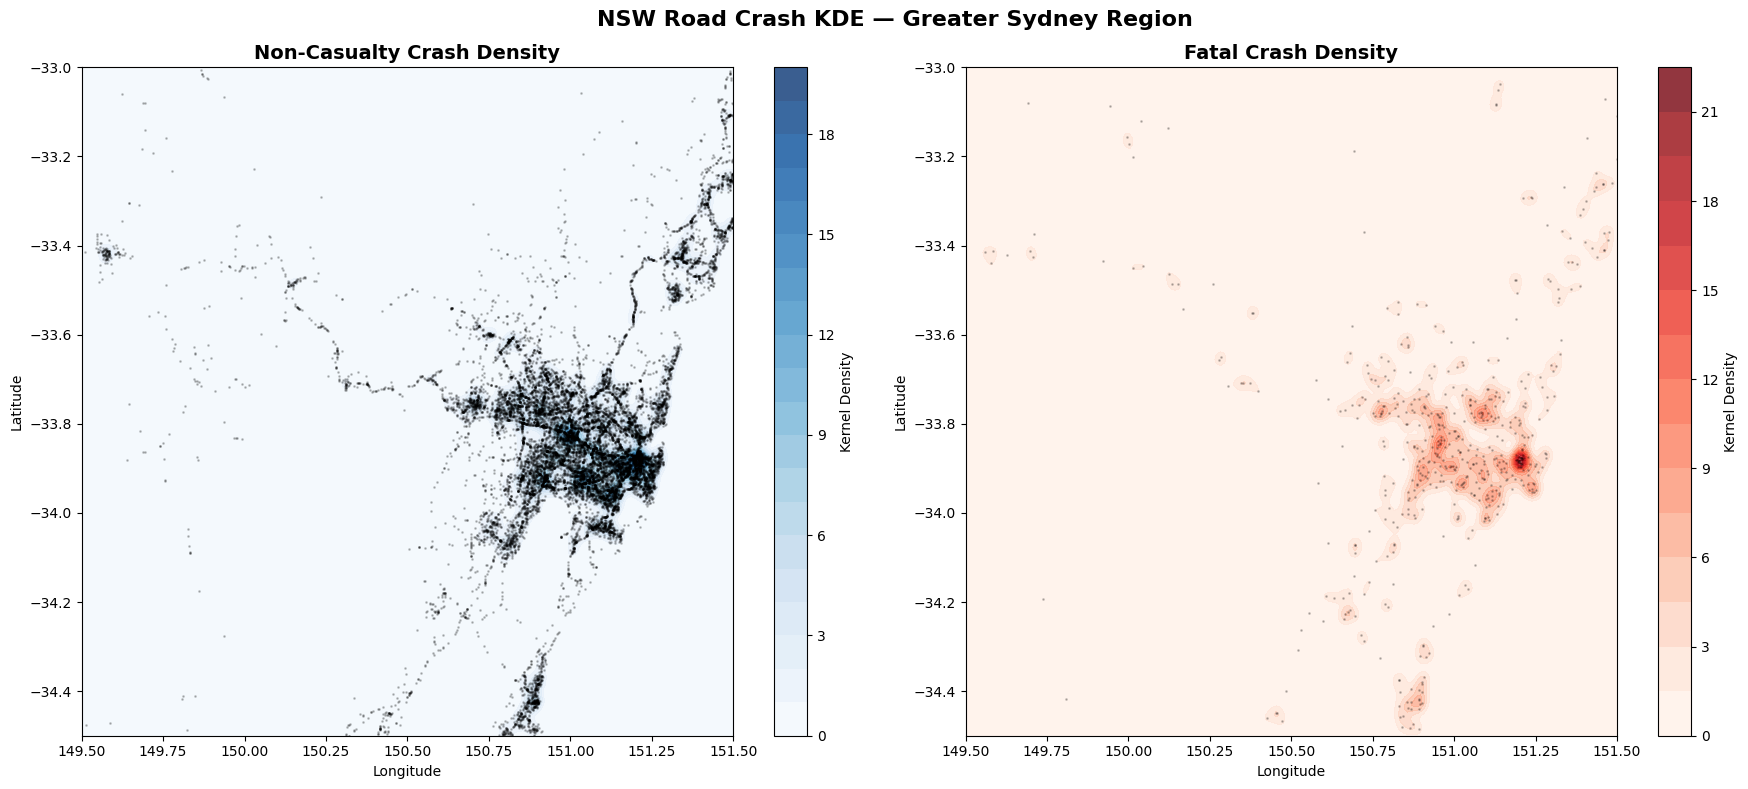

  Saved: gis_kde_density_sydney.png

=== Top 15 LGAs by Crash Risk Profile ===
                 lga  total_crashes  fatal_crashes  fatality_rate
canterbury-bankstown           4573             33           0.72
       central coast           4369             45           1.03
           blacktown           4295             34           0.79
              sydney           2932             23           0.78
          parramatta           2874             19           0.66
          cumberland           2837             24           0.85
           liverpool           2812             25           0.89
           fairfield           2481             22           0.89
          wollongong           2271             37           1.63
           newcastle           2254              7           0.31
      lake macquarie           2246             31           1.38
             penrith           2228             27           1.21
             bayside           2109             14           0.

In [33]:
"""
=============================================================
STEP 1: GIS HOTSPOT MAPPING
NSW Road Crash Risk Analysis — Week 9
=============================================================
Techniques used in this process:
  - Kernel Density Estimation (KDE) heatmap via Folium
  - Crash frequency grid (spatial binning)
  - Getis-Ord Gi* hotspot detection via PySAL (libpysal)
  - Severity-weighted hotspot map
=============================================================
"""

import pandas as pd
import numpy as np
import folium
from folium.plugins import HeatMap, HeatMapWithTime, MarkerCluster
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.stats import gaussian_kde
import warnings
warnings.filterwarnings('ignore')

# ── Loading data────────────────────────────────────────────────
crash = pd.read_csv('/content/drive/MyDrive/cleaned_crash_data.csv')

# Ensuring lat/lon are valid (NSW bounding box)
crash = crash[
    (crash['latitude'].between(-38, -28)) &
    (crash['longitude'].between(140, 154))
].copy()

print(f"Records with valid coordinates: {len(crash):,}")

# ── Severity weights ──────────────────────────────────────────
severity_weight = {'fatal': 10, 'injury': 3, 'non-casualty (towaway)': 1}
crash['severity_weight'] = crash['degree_of_crash'].map(severity_weight).fillna(1)


# ══════════════════════════════════════════════════════════════
#. MAP 1: Basic KDE Heatmap — all crashes
# ══════════════════════════════════════════════════════════════
print("\nGenerating Map 1: KDE Heatmap (all crashes)...")

heat_data = crash[['latitude', 'longitude']].dropna().values.tolist()

m1 = folium.Map(location=[-33.87, 151.21], zoom_start=9,
                tiles='CartoDB dark_matter')

HeatMap(
    heat_data,
    radius=12,
    blur=15,
    max_zoom=13,
    gradient={0.2: 'blue', 0.5: 'lime', 0.8: 'orange', 1.0: 'red'}
).add_to(m1)

folium.LayerControl().add_to(m1)
m1.save('gis_heatmap_all_crashes.html')
print("  Saved: gis_heatmap_all_crashes.html")


# ══════════════════════════════════════════════════════════════
#.  MAP 2: Severity-Weighted Heatmap
# ══════════════════════════════════════════════════════════════
print("\nGenerating Map 2: Severity-Weighted Heatmap...")

weighted_data = crash[['latitude', 'longitude', 'severity_weight']].dropna()
heat_weighted = weighted_data[['latitude', 'longitude', 'severity_weight']].values.tolist()

m2 = folium.Map(location=[-33.87, 151.21], zoom_start=9,
                tiles='CartoDB dark_matter')

HeatMap(
    heat_weighted,
    radius=15,
    blur=20,
    max_zoom=13,
    gradient={0.2: 'blue', 0.5: 'cyan', 0.7: 'yellow', 1.0: 'red'},
    min_opacity=0.3
).add_to(m2)

m2.save('gis_heatmap_severity_weighted.html')
print("  Saved: gis_heatmap_severity_weighted.html")


# ══════════════════════════════════════════════════════════════
# MAP 3: Fatal Crashes Only — Marker Cluster
# ══════════════════════════════════════════════════════════════
print("\nGenerating Map 3: Fatal crash locations...")

fatal = crash[crash['degree_of_crash'] == 'fatal'].dropna(subset=['latitude', 'longitude'])

m3 = folium.Map(location=[-33.87, 151.21], zoom_start=8,
                tiles='OpenStreetMap')

cluster = MarkerCluster(name='Fatal Crashes').add_to(m3)

for _, row in fatal.iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=6,
        color='red',
        fill=True,
        fill_color='darkred',
        fill_opacity=0.8,
        popup=folium.Popup(
            f"<b>Fatal Crash</b><br>"
            f"Date: {row.get('month_of_crash','?')} {row.get('year_of_crash','?')}<br>"
            f"Day: {row.get('day_of_week_of_crash','?')}<br>"
            f"Weather: {row.get('weather','?')}<br>"
            f"Speed Zone: {row.get('speed_limit','?')}<br>"
            f"LGA: {row.get('lga','?')}",
            max_width=250
        )
    ).add_to(cluster)

folium.LayerControl().add_to(m3)
m3.save('gis_fatal_crash_clusters.html')
print(f"  Saved: gis_fatal_crash_clusters.html  ({len(fatal):,} fatal crashes plotted)")


# ══════════════════════════════════════════════════════════════
#.  MAP 4: Temporal Heatmap (year-by-year animation)
# ══════════════════════════════════════════════════════════════
print("\nGenerating Map 4: Temporal heatmap by year...")

m4 = folium.Map(location=[-33.87, 151.21], zoom_start=9,
                tiles='CartoDB dark_matter')

yearly_data = []
years = sorted(crash['year_of_crash'].unique())
for yr in years:
    subset = crash[crash['year_of_crash'] == yr][['latitude', 'longitude']].dropna()
    yearly_data.append(subset.values.tolist())

HeatMapWithTime(
    yearly_data,
    index=[str(y) for y in years],
    radius=12,
    gradient={0.2: 'blue', 0.5: 'lime', 0.8: 'orange', 1.0: 'red'},
    min_opacity=0.3,
    max_opacity=0.8,
    use_local_extrema=True,
    name='Crashes by Year'
).add_to(m4)

m4.save('gis_temporal_heatmap.html')
print("  Saved: gis_temporal_heatmap.html")


# ══════════════════════════════════════════════════════════════
# MAP 5: Top LGA Risk Map (Choropleth-style marker map)
# ══════════════════════════════════════════════════════════════
print("\nGenerating Map 5: Top LGA crash summary markers...")

lga_stats = crash.groupby('lga').agg(
    total_crashes=('crash_id', 'count'),
    fatal_crashes=('degree_of_crash', lambda x: (x == 'fatal').sum()),
    avg_lat=('latitude', 'mean'),
    avg_lon=('longitude', 'mean')
).reset_index()

lga_stats['fatality_rate'] = (lga_stats['fatal_crashes'] / lga_stats['total_crashes'] * 100).round(2)
top_lgas = lga_stats.nlargest(20, 'total_crashes')

m5 = folium.Map(location=[-33.0, 147.0], zoom_start=6,
                tiles='OpenStreetMap')

def get_color(rate):
    if rate >= 2.0:   return 'darkred'
    elif rate >= 1.5: return 'red'
    elif rate >= 1.0: return 'orange'
    else:             return 'green'

for _, row in top_lgas.iterrows():
    folium.CircleMarker(
        location=[row['avg_lat'], row['avg_lon']],
        radius=max(8, min(30, row['total_crashes'] / 150)),
        color=get_color(row['fatality_rate']),
        fill=True,
        fill_opacity=0.7,
        popup=folium.Popup(
            f"<b>{row['lga'].title()}</b><br>"
            f"Total Crashes: {row['total_crashes']:,}<br>"
            f"Fatal Crashes: {row['fatal_crashes']}<br>"
            f"Fatality Rate: {row['fatality_rate']}%",
            max_width=200
        ),
        tooltip=f"{row['lga'].title()} — {row['total_crashes']:,} crashes"
    ).add_to(m5)

# Legend
legend_html = """
<div style="position:fixed; bottom:50px; left:50px; z-index:1000;
     background-color:white; padding:10px; border:2px solid grey; border-radius:5px;">
<b>Fatality Rate Legend</b><br>
<span style="color:darkred">●</span> ≥ 2.0% (Very High)<br>
<span style="color:red">●</span> 1.5–2.0% (High)<br>
<span style="color:orange">●</span> 1.0–1.5% (Medium)<br>
<span style="color:green">●</span> &lt; 1.0% (Lower)<br>
<i>Circle size = crash volume</i>
</div>
"""
m5.get_root().html.add_child(folium.Element(legend_html))
m5.save('gis_lga_risk_map.html')
print("  Saved: gis_lga_risk_map.html")


# ══════════════════════════════════════════════════════════════
#                 STATIC: KDE Density Plot (matplotlib)
# ══════════════════════════════════════════════════════════════
print("\nGenerating static KDE density plot...")

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for ax, label, title, cmap in zip(
    axes,
    ['non-casualty (towaway)', 'fatal'],
    ['Non-Casualty Crash Density', 'Fatal Crash Density'],
    ['Blues', 'Reds']
):
    subset = crash[crash['degree_of_crash'] == label].dropna(subset=['latitude', 'longitude'])
    lons = subset['longitude'].values
    lats = subset['latitude'].values

    xmin, xmax = 149.5, 151.5   # Sydney focus
    ymin, ymax = -34.5, -33.0

    mask = (lons > xmin) & (lons < xmax) & (lats > ymin) & (lats < ymax)
    lons_f, lats_f = lons[mask], lats[mask]

    if len(lons_f) > 50:
        xy = np.vstack([lons_f, lats_f])
        kde = gaussian_kde(xy, bw_method=0.05)
        xi = np.linspace(xmin, xmax, 200)
        yi = np.linspace(ymin, ymax, 200)
        xi_grid, yi_grid = np.meshgrid(xi, yi)
        zi = kde(np.vstack([xi_grid.ravel(), yi_grid.ravel()])).reshape(xi_grid.shape)

        im = ax.contourf(xi_grid, yi_grid, zi, levels=20, cmap=cmap, alpha=0.8)
        ax.scatter(lons_f, lats_f, s=1, alpha=0.2, c='black')
        plt.colorbar(im, ax=ax, label='Kernel Density')

    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

plt.suptitle('NSW Road Crash KDE — Greater Sydney Region', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('gis_kde_density_sydney.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Saved: gis_kde_density_sydney.png")


# ══════════════════════════════════════════════════════════════
#     LGA Summary Table
# ══════════════════════════════════════════════════════════════
print("\n=== Top 15 LGAs by Crash Risk Profile ===")
display_cols = ['lga', 'total_crashes', 'fatal_crashes', 'fatality_rate']
print(lga_stats.nlargest(15, 'total_crashes')[display_cols].to_string(index=False))

print("\n=== LGAs with Highest Fatality Rate (min 200 crashes) ===")
high_risk = lga_stats[lga_stats['total_crashes'] >= 200].nlargest(10, 'fatality_rate')
print(high_risk[display_cols].to_string(index=False))

**ML Model**

Crash data: (92082, 50)
Traffic data: (170747, 10)

=== Feature Engineering ===

Class distribution (3-class):
severity_3class
1    61187
0    29507
2     1388
Name: count, dtype: int64

Class distribution (binary):
severity_binary
0    90694
1     1388
Name: count, dtype: int64

=== Preparing Features ===
Feature matrix shape: (92082, 17)
Features used: ['weather', 'natural_lighting', 'surface_condition', 'road_classification_(admin)', 'urbanisation', 'type_of_location', 'alignment', 'key_vehicle_type', 'speed_limit_num', 'hour', 'no._of_traffic_units_involved', 'is_rush_hour', 'is_weekend', 'is_dark', 'is_bad_weather', 'is_wet_surface', 'in_school_zone']

=== Train/Test Split + SMOTE ===
Train size: 73,665 | Test size: 18,417
Fatal in train (before SMOTE): 1110 (1.51%)
After SMOTE — Train size: 145,110
Fatal in train (after SMOTE): 72555 (50.00%)

=== Training Models ===

--- Logistic Regression ---
ROC-AUC: 0.6539
              precision    recall  f1-score   support

   Non-Fatal  

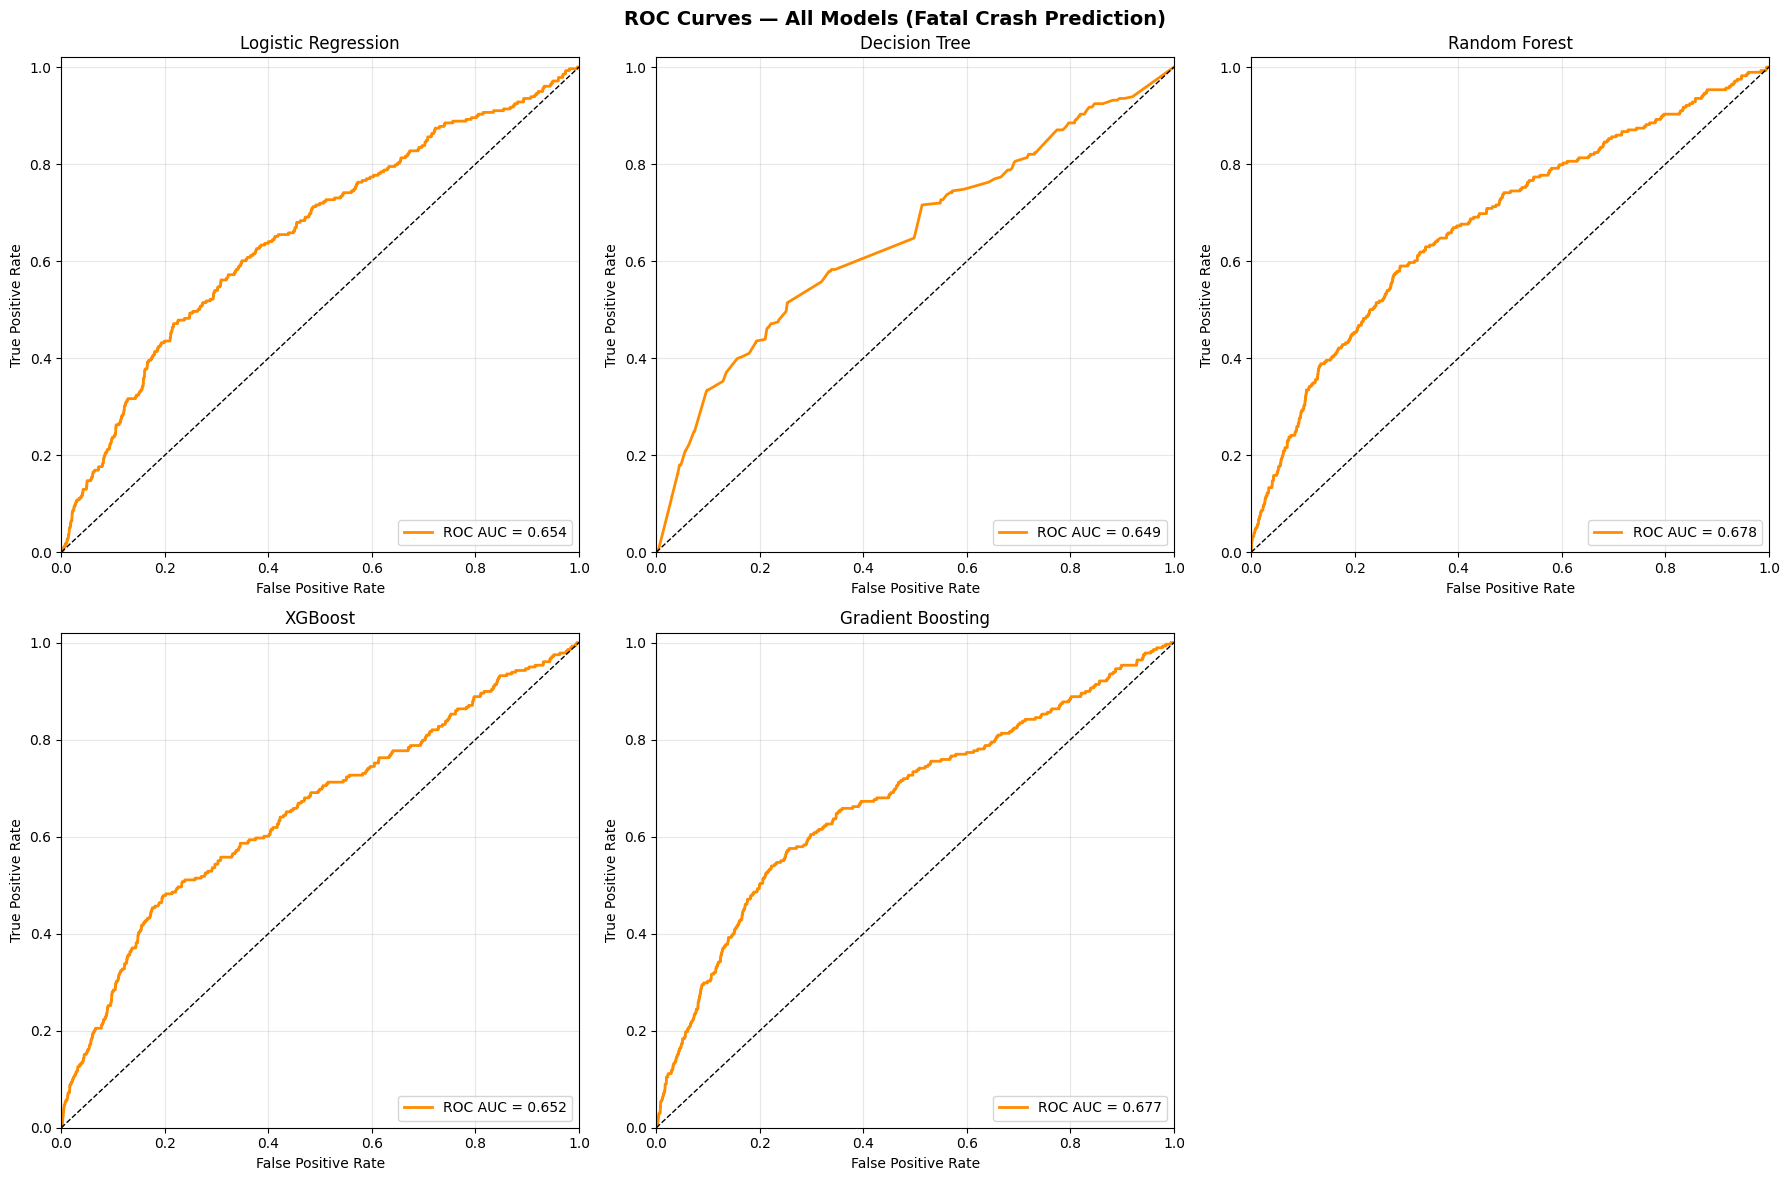


Saved: ml_roc_curves.png

=== Model Comparison ===
              Model  ROC-AUC  Accuracy  Fatal Precision  Fatal Recall  Fatal F1
      Random Forest   0.6784    0.8199           0.0358        0.4209    0.0659
  Gradient Boosting   0.6765    0.8683           0.0407        0.3417    0.0727
Logistic Regression   0.6539    0.7536           0.0296        0.4820    0.0558
            XGBoost   0.6518    0.3564           0.0180        0.7770    0.0352
      Decision Tree   0.6487    0.7709           0.0312        0.4712    0.0585


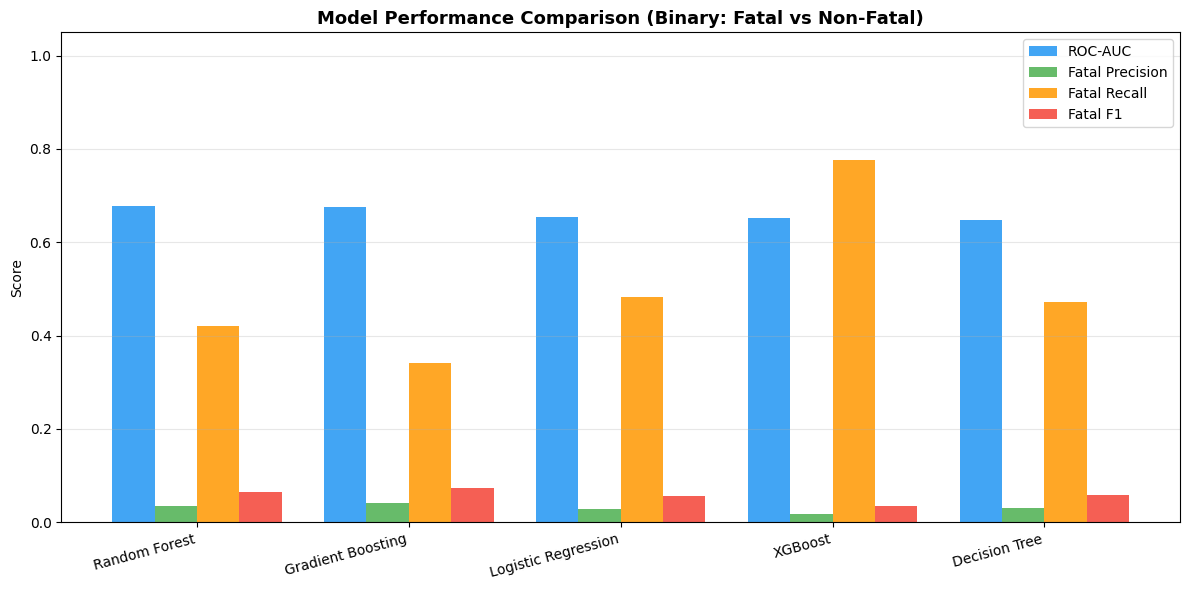

Saved: ml_model_comparison.png

=== Confusion Matrices ===


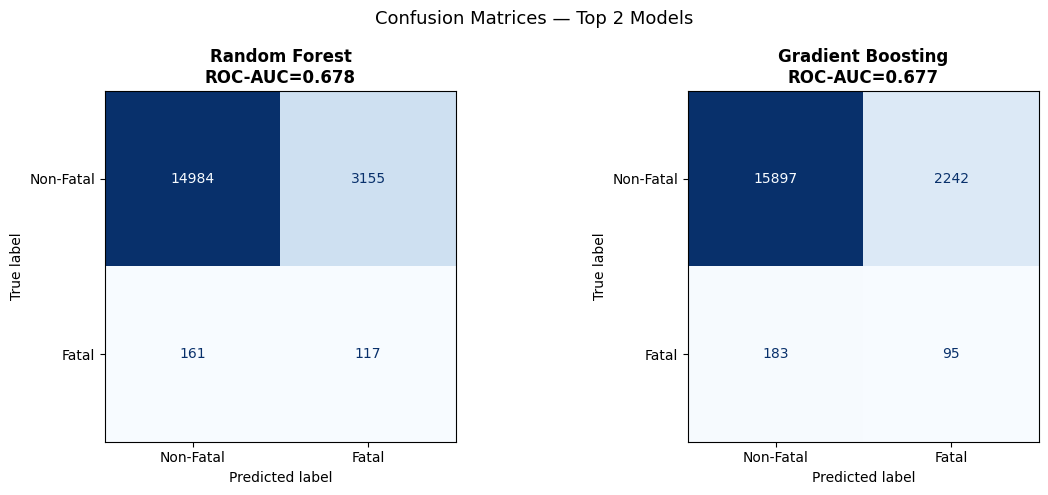

Saved: ml_confusion_matrices.png

=== Random Forest Feature Importance ===
                      Feature  Importance
                 urbanisation    0.149338
              speed_limit_num    0.141042
                    alignment    0.130308
             type_of_location    0.128857
                   is_weekend    0.078066
                         hour    0.064306
no._of_traffic_units_involved    0.062638
             key_vehicle_type    0.047646
                 is_rush_hour    0.032183
             natural_lighting    0.028863
  road_classification_(admin)    0.026464
                      weather    0.023977
            surface_condition    0.023686
               in_school_zone    0.019534
               is_wet_surface    0.016848
               is_bad_weather    0.013208
                      is_dark    0.013035


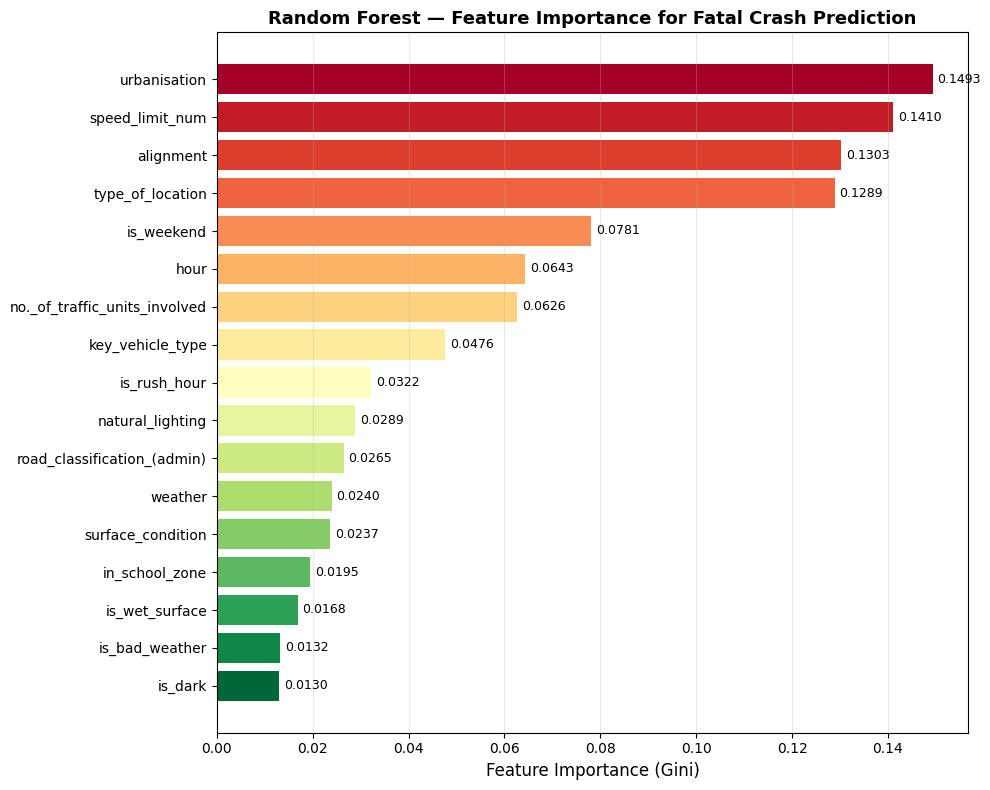

Saved: ml_rf_feature_importance.png

=== SHAP Analysis (XGBoost) ===


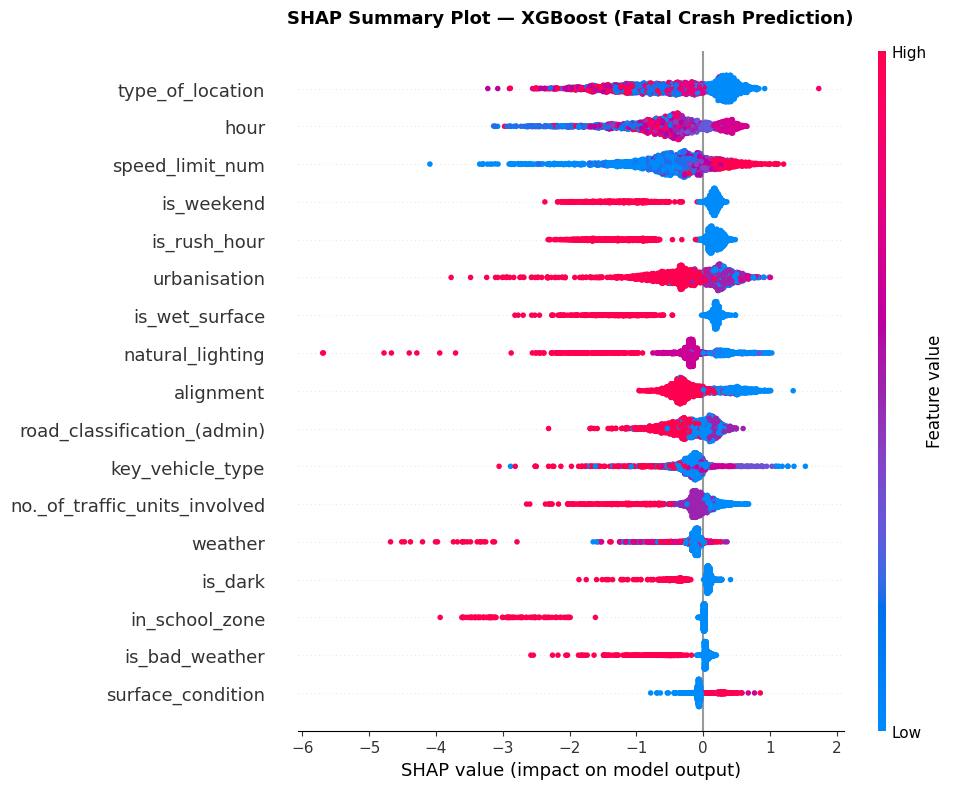

Saved: ml_shap_summary.png


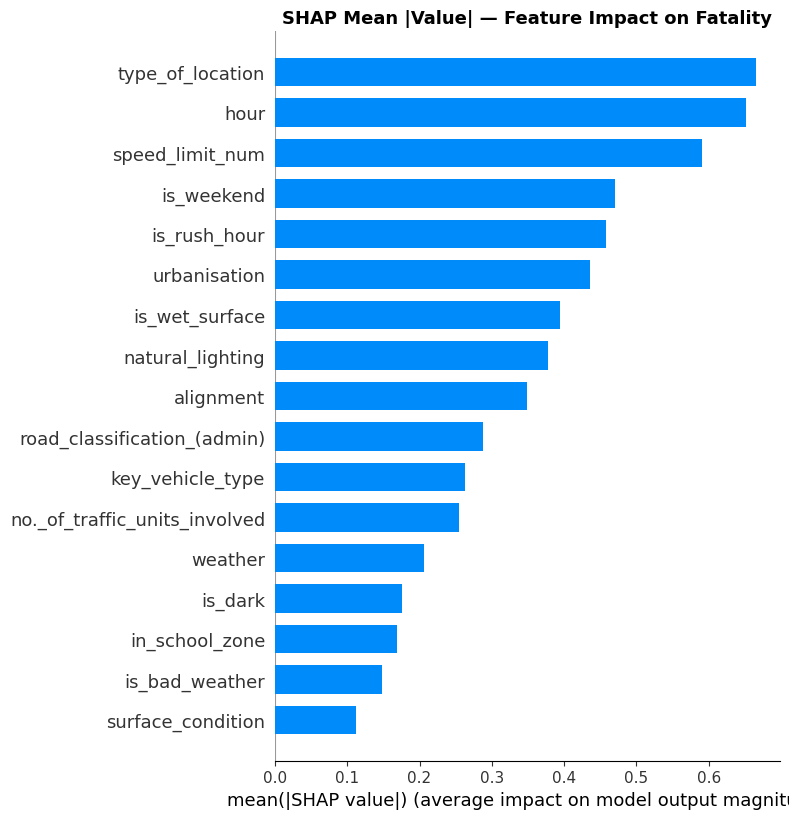

Saved: ml_shap_bar.png

=== Stratified 5-Fold Cross-Validation (Random Forest) ===
ROC-AUC per fold: ['0.6618', '0.6985', '0.6742', '0.6670', '0.6585']
Mean ROC-AUC:     0.6720 ± 0.0142

=== 3-Class Severity Model (Random Forest) ===
              precision    recall  f1-score   support

Non-Casualty       0.44      0.45      0.45      5901
      Injury       0.73      0.58      0.64     12238
       Fatal       0.04      0.38      0.07       278

    accuracy                           0.53     18417
   macro avg       0.40      0.47      0.39     18417
weighted avg       0.63      0.53      0.57     18417



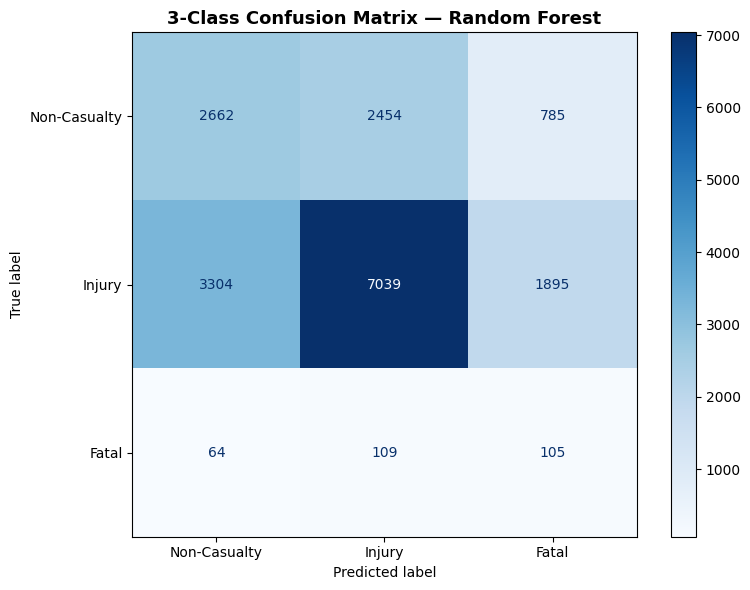

Saved: ml_3class_confusion.png

=== ALL MODELS COMPLETE ===
Best model by ROC-AUC: Random Forest (AUC=0.6784)


In [31]:
"""
=============================================================
STEP 2: ADVANCED MACHINE LEARNING MODELS
NSW Road Crash Risk Analysis — Week 10
=============================================================
Models:
  1. Random Forest (with SMOTE for class imbalance)
  2. XGBoost
  3. Decision Tree
  4. LightGBM (optional)
Extras:
  - SMOTE oversampling
  - Cross-validation
  - ROC curves
  - SHAP feature importance
  - Confusion matrices
=============================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, auc,
    ConfusionMatrixDisplay
)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

# SMOTE for class imbalance
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# XGBoost
from xgboost import XGBClassifier

# SHAP
import shap

# ── Load data ────────────────────────────────────────────────
crash = pd.read_csv('/content/drive/MyDrive/cleaned_crash_data.csv')
traffic = pd.read_csv('/content/drive/MyDrive/cleaned_traffic_data.csv')

print(f"Crash data: {crash.shape}")
print(f"Traffic data: {traffic.shape}")


# ══════════════════════════════════════════════════════════════
# SECTION A: FEATURE ENGINEERING
# ══════════════════════════════════════════════════════════════
print("\n=== Feature Engineering ===")

df = crash.copy()

# 1.Extracting hour from two hours interval
df['hour'] = df['two-hour_intervals'].astype(str).str.extract(r'(\d+):').astype(float)
df['hour'] = df['hour'].fillna(df['hour'].median())

# 2. Cleaning speed limit → numeric
df['speed_limit_num'] = (
    df['speed_limit']
    .astype(str)
    .str.replace(' km/h', '', regex=False)
    .replace('unknown', np.nan)
)
df['speed_limit_num'] = pd.to_numeric(df['speed_limit_num'])
df['speed_limit_num'] = df['speed_limit_num'].fillna(df['speed_limit_num'].median())

# 3. RUshing for Flag
df['is_rush_hour'] = df['hour'].isin([7, 8, 16, 17]).astype(int)

# 4. Weekend flag
df['is_weekend'] = df['day_of_week_of_crash'].isin(['saturday', 'sunday']).astype(int)

# 5. Darkness flag
df['is_dark'] = df['natural_lighting'].isin(['darkness']).astype(int)

# 6. Bad weather flag
df['is_bad_weather'] = df['weather'].isin(['raining', 'fog or mist', 'snowing']).astype(int)

# 7. Wet road flag
df['is_wet_surface'] = df['surface_condition'].isin(['wet', 'snow or ice']).astype(int)

# 8. School zone flag
df['in_school_zone'] = (df['school_zone_location'] == 'yes').astype(int)

# 9. Merging dominant vehicle type per crash from traffic data
key_tu = (
    traffic[traffic['tu_role_in_first_impact'] == 'key traffic unit']
    .drop_duplicates('crash_id')[['crash_id', 'tu_type_group']]
    .rename(columns={'tu_type_group': 'key_vehicle_type'})
)
df = df.merge(key_tu, on='crash_id', how='left')
df['key_vehicle_type'] = df['key_vehicle_type'].fillna('unknown')

# 10. Targeting variable — 3-class
df['severity_3class'] = df['degree_of_crash'].map({
    'fatal': 2,
    'injury': 1,
    'non-casualty (towaway)': 0
})

# 11. Targeting variable — binary (fatal vs non-fatal)
df['severity_binary'] = (df['degree_of_crash'] == 'fatal').astype(int)

print("\nClass distribution (3-class):")
print(df['severity_3class'].value_counts())
print("\nClass distribution (binary):")
print(df['severity_binary'].value_counts())


# ══════════════════════════════════════════════════════════════
# SECTION B: PREPARE FEATURES
# ══════════════════════════════════════════════════════════════
print("\n=== Preparing Features ===")

CATEGORICAL_FEATURES = [
    'weather', 'natural_lighting', 'surface_condition',
    'road_classification_(admin)', 'urbanisation',
    'type_of_location', 'alignment', 'key_vehicle_type'
]
NUMERIC_FEATURES = [
    'speed_limit_num', 'hour', 'no._of_traffic_units_involved',
    'is_rush_hour', 'is_weekend', 'is_dark',
    'is_bad_weather', 'is_wet_surface', 'in_school_zone'
]

feature_cols = CATEGORICAL_FEATURES + NUMERIC_FEATURES

X_raw = df[feature_cols].copy()
y_binary = df['severity_binary']
y_3class = df['severity_3class']

# Label-encode categoricals
le_dict = {}
for col in CATEGORICAL_FEATURES:
    le = LabelEncoder()
    X_raw[col] = X_raw[col].fillna('unknown').astype(str)
    X_raw[col] = le.fit_transform(X_raw[col])
    le_dict[col] = le

# Fill remaining NaN
X_raw = X_raw.fillna(0)

print(f"Feature matrix shape: {X_raw.shape}")
print(f"Features used: {feature_cols}")


# ══════════════════════════════════════════════════════════════
# SECTION C: TRAINing/TESTing SPLIT + SMOTE
# ══════════════════════════════════════════════════════════════
print("\n=== Train/Test Split + SMOTE ===")

X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y_binary, test_size=0.2, random_state=42, stratify=y_binary
)

print(f"Train size: {X_train.shape[0]:,} | Test size: {X_test.shape[0]:,}")
print(f"Fatal in train (before SMOTE): {y_train.sum()} ({y_train.mean()*100:.2f}%)")

# Applying SMOTE to train set only
smote = SMOTE(random_state=42, k_neighbors=5)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print(f"After SMOTE — Train size: {X_train_sm.shape[0]:,}")
print(f"Fatal in train (after SMOTE): {y_train_sm.sum()} ({y_train_sm.mean()*100:.2f}%)")

# Scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_sm)
X_test_scaled  = scaler.transform(X_test)


# ══════════════════════════════════════════════════════════════
# SECTION D: MODEL TRAINING & EVALUATION
# ══════════════════════════════════════════════════════════════
print("\n=== Training Models ===")

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
    'Decision Tree':       DecisionTreeClassifier(max_depth=8, random_state=42, class_weight='balanced'),
    'Random Forest':       RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42,
                                                   n_jobs=-1, class_weight='balanced'),
    'XGBoost':             XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1,
                                          random_state=42, eval_metric='logloss',
                                          scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum()),
    'Gradient Boosting':   GradientBoostingClassifier(n_estimators=100, max_depth=5,
                                                       learning_rate=0.1, random_state=42),
}

results = {}
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.ravel()

for i, (name, model) in enumerate(models.items()):
    print(f"\n--- {name} ---")

    # Using scaled data for LR; tree models can use unscaled
    if name == 'Logistic Regression':
        model.fit(X_train_scaled, y_train_sm)
        y_prob = model.predict_proba(X_test_scaled)[:, 1]
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train_sm, y_train_sm)
        y_prob = model.predict_proba(X_test)[:, 1]
        y_pred = model.predict(X_test)

    # Metrics
    roc_auc = roc_auc_score(y_test, y_prob)
    report  = classification_report(y_test, y_pred,
                                    target_names=['Non-Fatal', 'Fatal'],
                                    output_dict=True)

    results[name] = {
        'model':   model,
        'y_pred':  y_pred,
        'y_prob':  y_prob,
        'roc_auc': roc_auc,
        'report':  report,
    }

    print(f"ROC-AUC: {roc_auc:.4f}")
    print(classification_report(y_test, y_pred, target_names=['Non-Fatal', 'Fatal']))

    # ROC curve subplot
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    axes[i].plot(fpr, tpr, color='darkorange', lw=2,
                 label=f'ROC AUC = {roc_auc:.3f}')
    axes[i].plot([0, 1], [0, 1], 'k--', lw=1)
    axes[i].set_xlim([0, 1]); axes[i].set_ylim([0, 1.02])
    axes[i].set_xlabel('False Positive Rate')
    axes[i].set_ylabel('True Positive Rate')
    axes[i].set_title(f'{name}')
    axes[i].legend(loc='lower right')
    axes[i].grid(alpha=0.3)

# Hide last unused subplot
axes[-1].set_visible(False)

plt.suptitle('ROC Curves — All Models (Fatal Crash Prediction)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('ml_roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nSaved: ml_roc_curves.png")


# ══════════════════════════════════════════════════════════════
# SECTION E: MODEL COMPARISON TABLE
# ══════════════════════════════════════════════════════════════
print("\n=== Model Comparison ===")

summary_rows = []
for name, res in results.items():
    rep = res['report']
    fatal_metrics = rep.get('Fatal', {})
    summary_rows.append({
        'Model':          name,
        'ROC-AUC':        round(res['roc_auc'], 4),
        'Accuracy':       round(rep['accuracy'], 4),
        'Fatal Precision':round(fatal_metrics.get('precision', 0), 4),
        'Fatal Recall':   round(fatal_metrics.get('recall', 0), 4),
        'Fatal F1':       round(fatal_metrics.get('f1-score', 0), 4),
    })

summary_df = pd.DataFrame(summary_rows).sort_values('ROC-AUC', ascending=False)
print(summary_df.to_string(index=False))

# Bar chart comparison
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(summary_df))
width = 0.2

metrics = ['ROC-AUC', 'Fatal Precision', 'Fatal Recall', 'Fatal F1']
colors  = ['#2196F3', '#4CAF50', '#FF9800', '#F44336']

for j, (metric, color) in enumerate(zip(metrics, colors)):
    ax.bar(x + j * width, summary_df[metric], width, label=metric, color=color, alpha=0.85)

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(summary_df['Model'], rotation=15, ha='right')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.set_title('Model Performance Comparison (Binary: Fatal vs Non-Fatal)', fontsize=13, fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('ml_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: ml_model_comparison.png")


# ══════════════════════════════════════════════════════════════
# SECTION F: CONFUSION MATRICES (Best 2 models)
# ══════════════════════════════════════════════════════════════
print("\n=== Confusion Matrices ===")

best_two = summary_df.head(2)['Model'].tolist()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name in zip(axes, best_two):
    cm = confusion_matrix(y_test, results[name]['y_pred'])
    disp = ConfusionMatrixDisplay(cm, display_labels=['Non-Fatal', 'Fatal'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{name}\nROC-AUC={results[name]["roc_auc"]:.3f}', fontweight='bold')

plt.suptitle('Confusion Matrices — Top 2 Models', fontsize=13)
plt.tight_layout()
plt.savefig('ml_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: ml_confusion_matrices.png")


# ══════════════════════════════════════════════════════════════
# SECTION G: RANDOM FOREST FEATURE IMPORTANCE
# ══════════════════════════════════════════════════════════════
print("\n=== Random Forest Feature Importance ===")

rf_model = results['Random Forest']['model']
importance_df = pd.DataFrame({
    'Feature':   feature_cols,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

print(importance_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 8))
colors = plt.cm.RdYlGn_r(np.linspace(0, 1, len(importance_df)))
bars = ax.barh(importance_df['Feature'][::-1],
               importance_df['Importance'][::-1], color=colors)
ax.set_xlabel('Feature Importance (Gini)', fontsize=12)
ax.set_title('Random Forest — Feature Importance for Fatal Crash Prediction',
             fontsize=13, fontweight='bold')
ax.grid(axis='x', alpha=0.3)

for bar, val in zip(bars, importance_df['Importance'][::-1]):
    ax.text(val + 0.001, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('ml_rf_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: ml_rf_feature_importance.png")


# ══════════════════════════════════════════════════════════════
# SECTION H: SHAPing VALUES (XGBoost)
# ══════════════════════════════════════════════════════════════
print("\n=== SHAP Analysis (XGBoost) ===")

xgb_model = results['XGBoost']['model']

# Use a sample for SHAP speed
sample_idx = np.random.choice(len(X_test), size=min(2000, len(X_test)), replace=False)
X_sample = X_test.iloc[sample_idx]

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_sample)

# Summarizing plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_sample,
                  feature_names=feature_cols,
                  show=False, plot_size=(10, 8))
plt.title('SHAP Summary Plot — XGBoost (Fatal Crash Prediction)',
          fontsize=13, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('ml_shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: ml_shap_summary.png")

# Bar plot
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values, X_sample,
                  feature_names=feature_cols,
                  plot_type='bar', show=False)
plt.title('SHAP Mean |Value| — Feature Impact on Fatality', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('ml_shap_bar.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: ml_shap_bar.png")


# ══════════════════════════════════════════════════════════════
# SECTION I: CROSS-VALIDATION (Best model = Random Forest)
# ══════════════════════════════════════════════════════════════
print("\n=== Stratified 5-Fold Cross-Validation (Random Forest) ===")

rf_cv = RandomForestClassifier(n_estimators=100, max_depth=10,
                                random_state=42, n_jobs=-1,
                                class_weight='balanced')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# NOTE: Apply SMOTE per fold for proper CV (using imblearn pipeline)
from imblearn.pipeline import Pipeline as ImbPipeline

pipe = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('rf',    rf_cv)
])

cv_scores = cross_val_score(pipe, X_raw, y_binary,
                             cv=cv, scoring='roc_auc', n_jobs=-1)

print(f"ROC-AUC per fold: {[f'{s:.4f}' for s in cv_scores]}")
print(f"Mean ROC-AUC:     {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")


# ══════════════════════════════════════════════════════════════
# SECTION J: 3-CLASS MODEL (fatal / injury / non-casualty)
# ══════════════════════════════════════════════════════════════
print("\n=== 3-Class Severity Model (Random Forest) ===")

X_train3, X_test3, y_train3, y_test3 = train_test_split(
    X_raw, y_3class, test_size=0.2, random_state=42, stratify=y_3class
)

smote3 = SMOTE(random_state=42, k_neighbors=3)
X_train3_sm, y_train3_sm = smote3.fit_resample(X_train3, y_train3)

rf3 = RandomForestClassifier(n_estimators=100, max_depth=10,
                              random_state=42, n_jobs=-1,
                              class_weight='balanced')
rf3.fit(X_train3_sm, y_train3_sm)
y_pred3 = rf3.predict(X_test3)

print(classification_report(y_test3, y_pred3,
      target_names=['Non-Casualty', 'Injury', 'Fatal']))

# Multi-class confusion matrix
cm3 = confusion_matrix(y_test3, y_pred3)
fig, ax = plt.subplots(figsize=(8, 6))
disp3 = ConfusionMatrixDisplay(cm3,
    display_labels=['Non-Casualty', 'Injury', 'Fatal'])
disp3.plot(ax=ax, colorbar=True, cmap='Blues')
ax.set_title('3-Class Confusion Matrix — Random Forest', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('ml_3class_confusion.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: ml_3class_confusion.png")

print("\n=== ALL MODELS COMPLETE ===")
print(f"Best model by ROC-AUC: {summary_df.iloc[0]['Model']} (AUC={summary_df.iloc[0]['ROC-AUC']})")

**Pattern Discovery**

=== Cramér's V Association Matrix ===


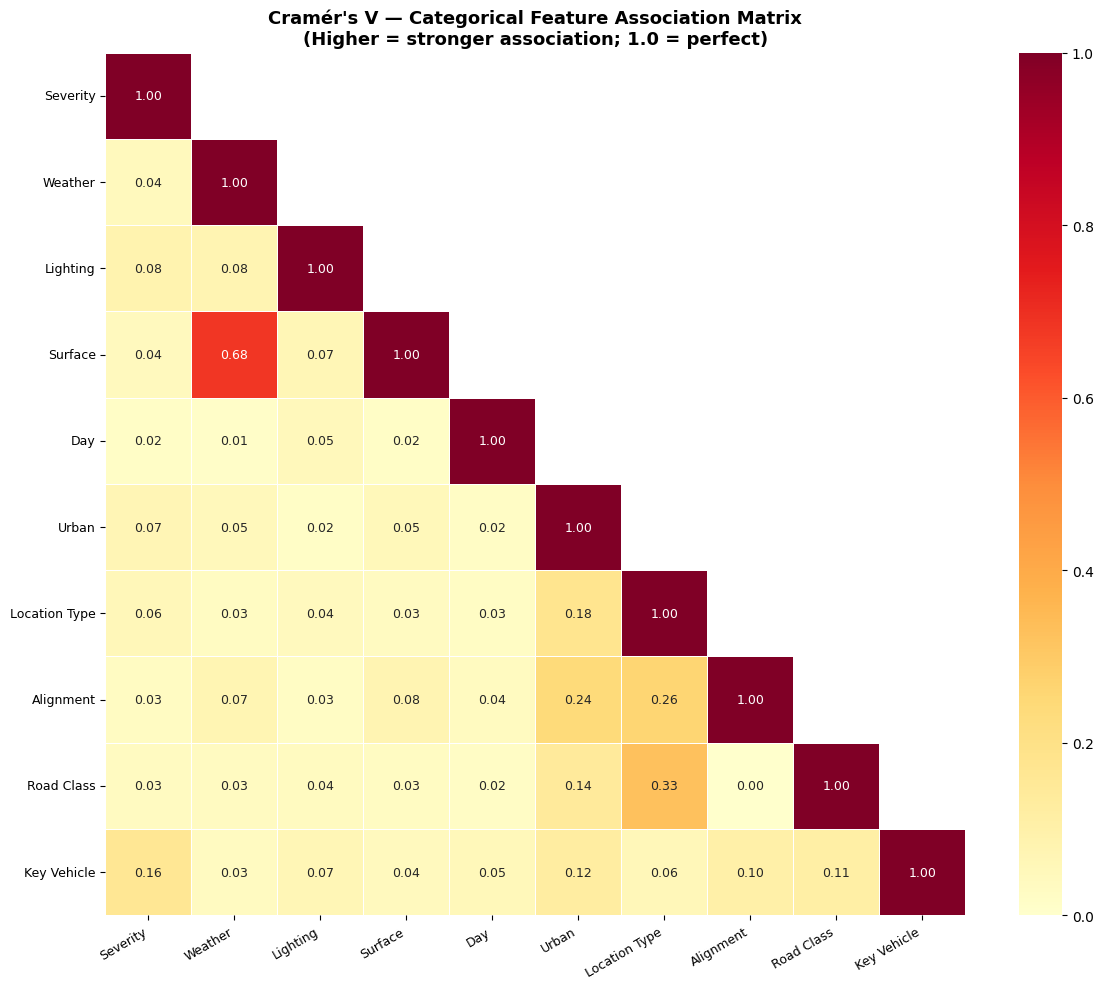

Saved: pattern_cramersv_matrix.png

=== Fatality Rate Heatmaps ===


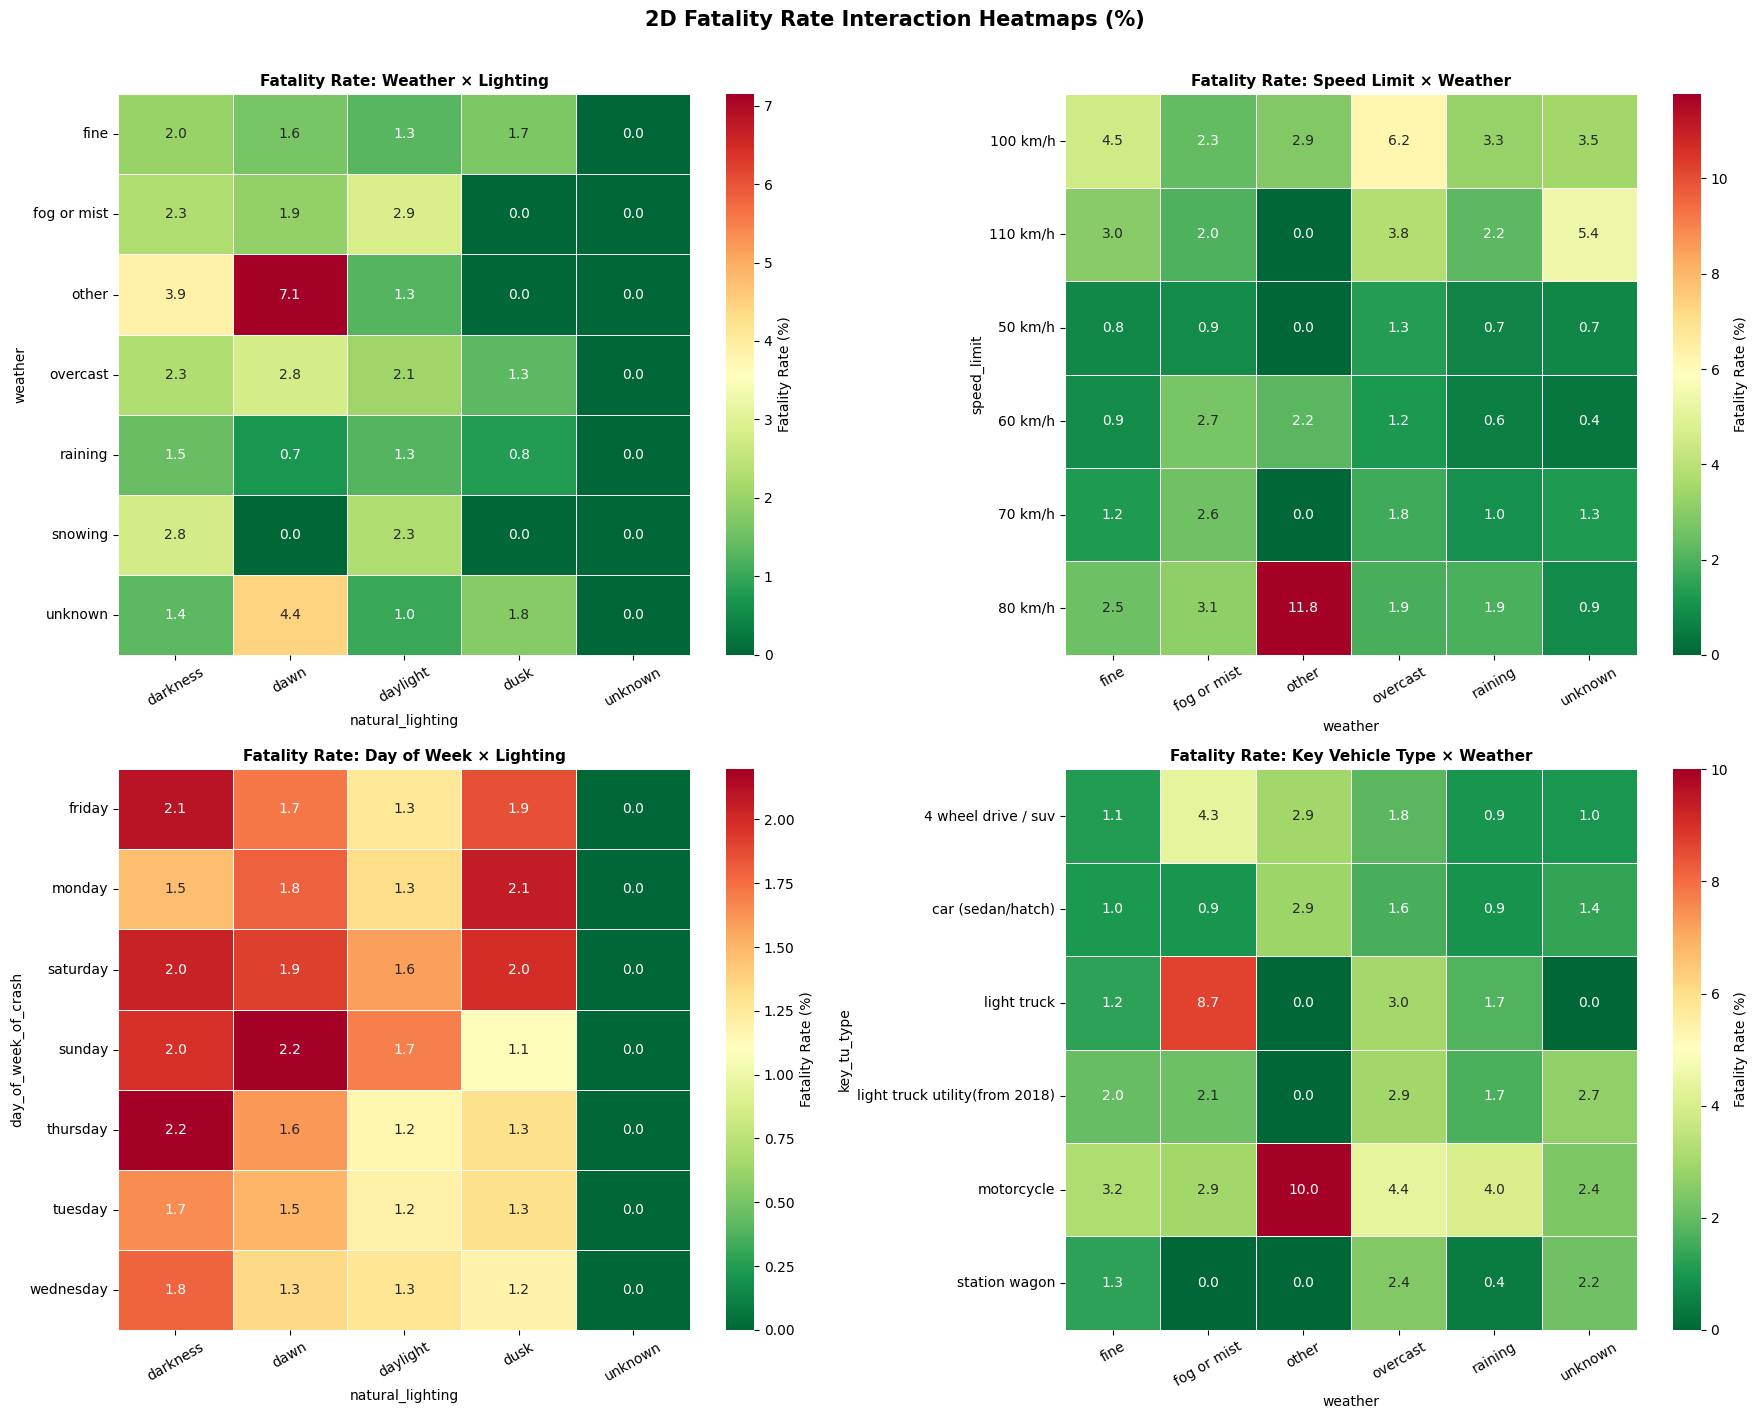

Saved: pattern_fatality_heatmaps.png

=== Seasonal Decomposition ===


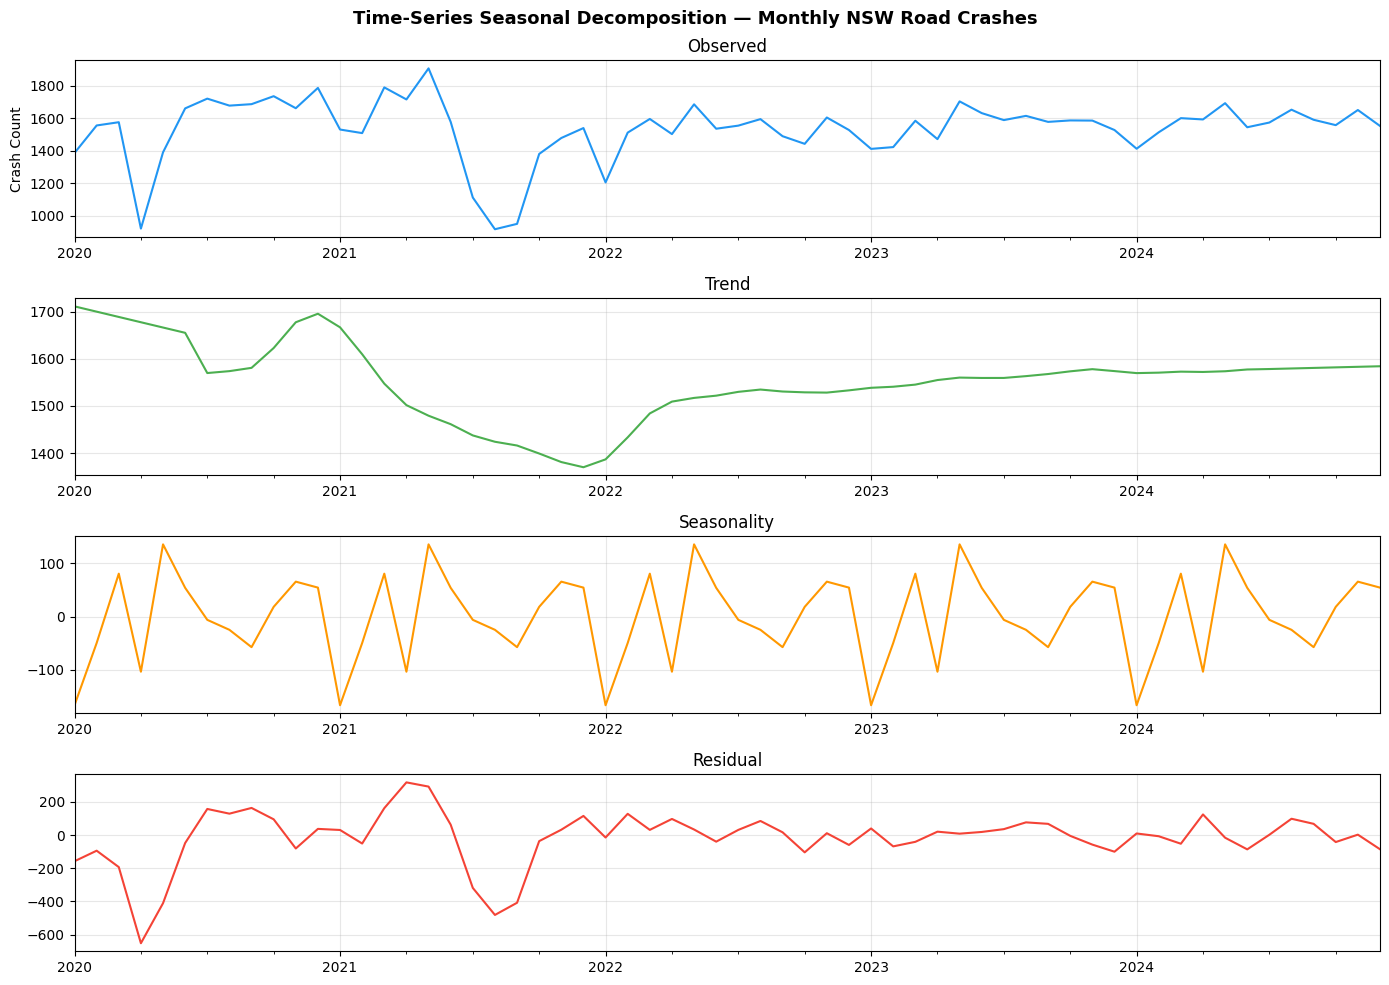

Saved: pattern_seasonal_decomposition.png

Monthly Seasonality Indices (avg crash above/below trend):
date
2020-01-31   -166.3
2020-02-29    -49.6
2020-03-31     80.4
2020-04-30   -103.4
2020-05-31    135.4
2020-06-30     53.9
2020-07-31     -6.1
2020-08-31    -24.9
2020-09-30    -57.3
2020-10-31     18.2
2020-11-30     65.5
2020-12-31     54.3
2021-01-31   -166.3
2021-02-28    -49.6
2021-03-31     80.4
2021-04-30   -103.4
2021-05-31    135.4
2021-06-30     53.9
2021-07-31     -6.1
2021-08-31    -24.9
2021-09-30    -57.3
2021-10-31     18.2
2021-11-30     65.5
2021-12-31     54.3
2022-01-31   -166.3
2022-02-28    -49.6
2022-03-31     80.4
2022-04-30   -103.4
2022-05-31    135.4
2022-06-30     53.9
2022-07-31     -6.1
2022-08-31    -24.9
2022-09-30    -57.3
2022-10-31     18.2
2022-11-30     65.5
2022-12-31     54.3
2023-01-31   -166.3
2023-02-28    -49.6
2023-03-31     80.4
2023-04-30   -103.4
2023-05-31    135.4
2023-06-30     53.9
2023-07-31     -6.1
2023-08-31    -24.9
2023-09-30   

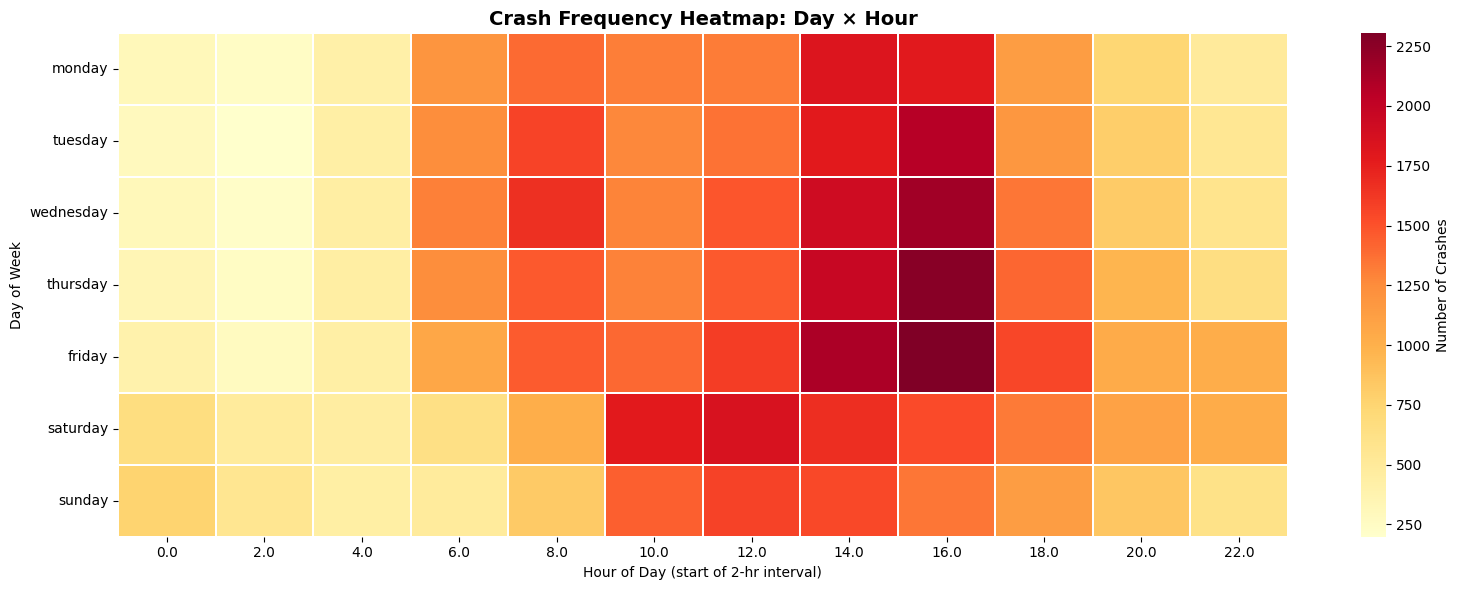

Saved: pattern_day_hour_heatmap.png

=== Chi-Square Tests: All Features vs Crash Severity ===
                    Feature  Chi2 Stat   P-value  Cramér's V Significant Effect Size
                key_tu_type    4839.63  0.00e+00      0.1609           ✓      Medium
                speed_limit    1476.56 3.15e-299      0.0889           ✓       Small
           natural_lighting    1259.90 1.09e-266      0.0825           ✓       Small
               urbanisation     904.86 5.72e-188      0.0697           ✓       Small
           type_of_location     630.79 8.47e-118      0.0574           ✓       Small
                    weather     361.62  4.95e-70      0.0436           ✓       Small
          surface_condition     323.08  9.23e-67      0.0415           ✓       Small
road_classification_(admin)     207.24  1.04e-43      0.0332           ✓       Small
                  alignment     177.97  2.04e-37      0.0307           ✓       Small
       day_of_week_of_crash      73.27  7.78e-11      0.

In [32]:
"""
=============================================================
BONUS: PATTERN DISCOVERY & FEATURE INTERACTION ANALYSIS
NSW Road Crash Risk Analysis
=============================================================
This code bridges your EDA and ML sections with deeper
statistical interaction analysis:
  - Chi-square tests for all categorical pairs
  - Cramér's V heatmap (association strength)
  - Fatality rate heatmaps (2D risk grids)
  - Seasonal decomposition
=============================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from statsmodels.tsa.seasonal import seasonal_decompose
import warnings
warnings.filterwarnings('ignore')

crash = pd.read_csv('/content/drive/MyDrive/cleaned_crash_data.csv')
traffic = pd.read_csv('/content/drive/MyDrive/cleaned_traffic_data.csv')


# ══════════════════════════════════════════════════════════════
# 1. Cramér's V — Associating between all categorical features
# ══════════════════════════════════════════════════════════════
print("=== Cramér's V Association Matrix ===")

def cramers_v(x, y):
    """Cramér's V statistic for categorical association."""
    ct = pd.crosstab(x, y)
    chi2, _, _, _ = chi2_contingency(ct)
    n = ct.values.sum()
    phi2 = chi2 / n
    r, k = ct.shape
    phi2_corr = max(0, phi2 - ((k-1)*(r-1)) / (n-1))
    r_corr = r - ((r-1)**2) / (n-1)
    k_corr = k - ((k-1)**2) / (n-1)
    denom = min(k_corr-1, r_corr-1)
    return np.sqrt(phi2_corr / denom) if denom > 0 else 0

cat_cols = ['degree_of_crash', 'weather', 'natural_lighting',
            'surface_condition', 'day_of_week_of_crash',
            'urbanisation', 'type_of_location', 'alignment',
            'road_classification_(admin)', 'key_tu_type']

# Computing pairwise Cramér's V
n_cols = len(cat_cols)
v_matrix = np.zeros((n_cols, n_cols))

for i, c1 in enumerate(cat_cols):
    for j, c2 in enumerate(cat_cols):
        if i == j:
            v_matrix[i, j] = 1.0
        elif i < j:
            v = cramers_v(crash[c1].astype(str), crash[c2].astype(str))
            v_matrix[i, j] = v
            v_matrix[j, i] = v

v_df = pd.DataFrame(v_matrix, index=cat_cols, columns=cat_cols)

# Labeling (shorter)
labels = ['Severity', 'Weather', 'Lighting', 'Surface',
          'Day', 'Urban', 'Location Type', 'Alignment',
          'Road Class', 'Key Vehicle']

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.zeros_like(v_df, dtype=bool)
mask[np.triu_indices_from(mask, k=1)] = True

sns.heatmap(v_df,
            annot=True, fmt='.2f',
            cmap='YlOrRd',
            mask=mask,
            xticklabels=labels,
            yticklabels=labels,
            vmin=0, vmax=1,
            linewidths=0.5,
            ax=ax,
            annot_kws={'size': 9})

ax.set_title("Cramér's V — Categorical Feature Association Matrix\n"
             "(Higher = stronger association; 1.0 = perfect)",
             fontsize=13, fontweight='bold')
plt.xticks(rotation=30, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.savefig('pattern_cramersv_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: pattern_cramersv_matrix.png")


# ══════════════════════════════════════════════════════════════
# 2. Fatality Rate Heatmaps (2D Risk Grids)
# ══════════════════════════════════════════════════════════════
print("\n=== Fatality Rate Heatmaps ===")

def fatality_heatmap(df, col1, col2, ax, title, top_n=8):
    """Plot 2D fatality rate heatmap for two categorical features."""
    ct = pd.crosstab(df[col1], df[col2])
    fatal_ct = pd.crosstab(
        df[col1],
        df[col2],
        values=(df['degree_of_crash'] == 'fatal').astype(int),
        aggfunc='sum'
    ).fillna(0)

    rate = (fatal_ct / ct * 100).fillna(0)

    # Keeping top N categories for readability
    top_rows = ct.sum(axis=1).nlargest(top_n).index
    top_cols = ct.sum(axis=0).nlargest(top_n).index
    rate_filtered = rate.loc[
        rate.index.isin(top_rows),
        rate.columns.isin(top_cols)
    ]

    sns.heatmap(rate_filtered, annot=True, fmt='.1f',
                cmap='RdYlGn_r', linewidths=0.5, ax=ax,
                cbar_kws={'label': 'Fatality Rate (%)'})
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.tick_params(axis='x', rotation=30)
    ax.tick_params(axis='y', rotation=0)

fig, axes = plt.subplots(2, 2, figsize=(18, 14))

fatality_heatmap(crash, 'weather', 'natural_lighting', axes[0, 0],
                 'Fatality Rate: Weather × Lighting')

fatality_heatmap(crash, 'speed_limit', 'weather', axes[0, 1],
                 'Fatality Rate: Speed Limit × Weather', top_n=6)

fatality_heatmap(crash, 'day_of_week_of_crash', 'natural_lighting', axes[1, 0],
                 'Fatality Rate: Day of Week × Lighting')

fatality_heatmap(crash, 'key_tu_type', 'weather', axes[1, 1],
                 'Fatality Rate: Key Vehicle Type × Weather', top_n=6)

plt.suptitle('2D Fatality Rate Interaction Heatmaps (%)',
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('pattern_fatality_heatmaps.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: pattern_fatality_heatmaps.png")


# ══════════════════════════════════════════════════════════════
# 3. Time-Series Seasonal Decomposition
# ══════════════════════════════════════════════════════════════
print("\n=== Seasonal Decomposition ===")

month_order = ['january','february','march','april','may','june',
               'july','august','september','october','november','december']
month_num   = {m: i+1 for i, m in enumerate(month_order)}

monthly = crash.groupby(['year_of_crash', 'month_of_crash']).size().reset_index(name='count')
monthly['month_num'] = monthly['month_of_crash'].map(month_num)
monthly = monthly.sort_values(['year_of_crash', 'month_num'])
monthly['date'] = pd.to_datetime(
    monthly['year_of_crash'].astype(str) + '-' +
    monthly['month_num'].astype(str).str.zfill(2) + '-01'
)
monthly = monthly.set_index('date')['count']

# Decomposing (period=12 for monthly seasonality)
decomp = seasonal_decompose(monthly, model='additive', period=12, extrapolate_trend='freq')

fig, axes = plt.subplots(4, 1, figsize=(14, 10))
decomp.observed.plot(ax=axes[0], title='Observed', color='#2196F3')
decomp.trend.plot(ax=axes[1], title='Trend', color='#4CAF50')
decomp.seasonal.plot(ax=axes[2], title='Seasonality', color='#FF9800')
decomp.resid.plot(ax=axes[3], title='Residual', color='#F44336')

for ax in axes:
    ax.grid(alpha=0.3)
    ax.set_xlabel('')

axes[0].set_ylabel('Crash Count')
plt.suptitle('Time-Series Seasonal Decomposition — Monthly NSW Road Crashes',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('pattern_seasonal_decomposition.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: pattern_seasonal_decomposition.png")

# Print seasonal indices
print("\nMonthly Seasonality Indices (avg crash above/below trend):")
seasonal_by_month = decomp.seasonal.resample('M').mean()
print(seasonal_by_month.round(1))


# ══════════════════════════════════════════════════════════════
# 4. Hour × Day Crash Heatmap (Risk Grid)
# ══════════════════════════════════════════════════════════════
print("\n=== Hour × Day Crash Heatmap ===")

day_order = ['monday','tuesday','wednesday','thursday','friday','saturday','sunday']

# Extract start hour
crash['hour'] = crash['two-hour_intervals'].astype(str).str.extract(r'(\d+):').astype(float)
crash = crash[crash['hour'].notna()]

pivot = crash.pivot_table(
    index='day_of_week_of_crash',
    columns='hour',
    values='crash_id',
    aggfunc='count',
    fill_value=0
)
pivot = pivot.reindex([d for d in day_order if d in pivot.index])

fig, ax = plt.subplots(figsize=(16, 6))
sns.heatmap(pivot,
            cmap='YlOrRd',
            linewidths=0.3,
            ax=ax,
            cbar_kws={'label': 'Number of Crashes'})
ax.set_title('Crash Frequency Heatmap: Day × Hour', fontsize=14, fontweight='bold')
ax.set_xlabel('Hour of Day (start of 2-hr interval)')
ax.set_ylabel('Day of Week')
plt.tight_layout()
plt.savefig('pattern_day_hour_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: pattern_day_hour_heatmap.png")


# ══════════════════════════════════════════════════════════════
# 5. Chi-Square Summary Table (all pairs vs severity)
# ══════════════════════════════════════════════════════════════
print("\n=== Chi-Square Tests: All Features vs Crash Severity ===")

test_features = ['weather', 'natural_lighting', 'surface_condition',
                 'day_of_week_of_crash', 'urbanisation', 'type_of_location',
                 'alignment', 'road_classification_(admin)',
                 'key_tu_type', 'speed_limit']

chi2_results = []
for feat in test_features:
    ct = pd.crosstab(crash[feat], crash['degree_of_crash'])
    chi2, p, dof, _ = chi2_contingency(ct)
    v = cramers_v(crash[feat].astype(str), crash['degree_of_crash'].astype(str))
    chi2_results.append({
        'Feature':     feat,
        'Chi2 Stat':   round(chi2, 2),
        'P-value':     f'{p:.2e}',
        "Cramér's V":  round(v, 4),
        'Significant': '✓' if p < 0.05 else '✗',
        'Effect Size': 'Large' if v > 0.35 else ('Medium' if v > 0.15 else 'Small')
    })

chi2_df = pd.DataFrame(chi2_results).sort_values("Cramér's V", ascending=False)
print(chi2_df.to_string(index=False))

chi2_df.to_csv('/content/drive/MyDrive/pattern_chisquare_results.csv', index=False)
print("\nSaved: pattern_chisquare_results.csv")

In [ ]:
# ═══════════════════════════════════════════════════════════════
# STEP 3: POWER BI DASHBOARD
# ═══════════════════════════════════════════════════════════════

# Crash summary by LGA
lga_summary = crash.groupby('lga').agg(
    total_crashes       = ('crash_id', 'count'),
    fatal_crashes       = ('degree_of_crash', lambda x: (x == 'fatal').sum()),
    injury_crashes      = ('degree_of_crash', lambda x: (x == 'injury').sum()),
    noncasualty_crashes = ('degree_of_crash', lambda x: (x == 'non-casualty (towaway)').sum()),
    avg_lat             = ('latitude', 'mean'),
    avg_lon             = ('longitude', 'mean'),
    total_killed        = ('no._killed', 'sum'),
    total_seriously_inj = ('no._seriously_injured', 'sum'),
).reset_index()
lga_summary['fatality_rate_pct'] = (
    lga_summary['fatal_crashes'] / lga_summary['total_crashes'] * 100
).round(2)
lga_summary.to_csv('/content/drive/MyDrive/pbi_lga_summary.csv', index=False)

# Monthly trend table
month_order = ['january','february','march','april','may','june',
               'july','august','september','october','november','december']
month_num   = {m: i+1 for i, m in enumerate(month_order)}

monthly = crash.groupby(['year_of_crash', 'month_of_crash']).agg(
    total_crashes  = ('crash_id', 'count'),
    fatal_crashes  = ('degree_of_crash', lambda x: (x == 'fatal').sum()),
    injury_crashes = ('degree_of_crash', lambda x: (x == 'injury').sum()),
).reset_index()
monthly['month_num'] = monthly['month_of_crash'].map(month_num)
monthly = monthly.sort_values(['year_of_crash', 'month_num'])
monthly.to_csv('/content/drive/MyDrive/pbi_monthly_trend.csv', index=False)

# Day + hour distribution
time_dist = crash.groupby(['day_of_week_of_crash', 'two-hour_intervals']).agg(
    crashes = ('crash_id', 'count'),
    fatals   = ('degree_of_crash', lambda x: (x == 'fatal').sum()),
).reset_index()
time_dist.to_csv('/content/drive/MyDrive/pbi_time_distribution.csv', index=False)

# Weather × severity
weather_sev = crash.groupby(['weather', 'degree_of_crash']).size()\
              .reset_index(name='count')
weather_sev.to_csv('/content/drive/MyDrive/pbi_weather_severity.csv', index=False)

# Vehicle type × severity (merged)
vehicle_sev = traffic.merge(
    crash[['crash_id', 'degree_of_crash']], on='crash_id', how='left'
)
vehicle_summary = vehicle_sev.groupby(['tu_type_group', 'degree_of_crash'])\
                  .size().reset_index(name='count')
vehicle_summary.to_csv('/content/drive/MyDrive/pbi_vehicle_severity.csv', index=False)

# 6. Speed limit × severity
speed_sev = crash.groupby(['speed_limit', 'degree_of_crash']).size()\
            .reset_index(name='count')
speed_sev.to_csv('/content/drive/MyDrive/pbi_speed_severity.csv', index=False)

# 7. Crashing points (sample 15k for map performance)
map_data = crash[['crash_id', 'latitude', 'longitude',
                   'degree_of_crash', 'year_of_crash',
                   'month_of_crash', 'lga', 'speed_limit',
                   'weather', 'natural_lighting']]\
           .dropna(subset=['latitude', 'longitude'])

# Sample made for performance (as Power BI map visuals slow with 90k points)
map_sample = map_data.sample(n=min(15000, len(map_data)), random_state=42)
map_sample.to_csv('/content/drive/MyDrive/pbi_crash_map_points.csv', index=False)

print("All Power BI CSVs exported to Google Drive!")
print("Files created:")
for f in ['pbi_lga_summary', 'pbi_monthly_trend', 'pbi_time_distribution',
          'pbi_weather_severity', 'pbi_vehicle_severity',
          'pbi_speed_severity', 'pbi_crash_map_points']:
    print(f"  /content/drive/MyDrive/{f}.csv")